# Household Education Expenditure in Iran, 1394 and 1403

Setayesh Heydari and Bardia Soltani Moakhar  
Econometrics, School of Industrial Engineering, Sharif University of Technology  
Instructor: Dr. Fatemeh Asghari

We examine how household resources and family composition relate to education spending in two survey waves. The analysis compares positive-spending regressions with models that include households reporting zero.

Sections 1–4 introduce the question and data; 5–10 cover estimation and diagnostics; 11 compares waves; 12 reports sensitivity checks; and 13 discusses limitations.

The displayed outputs document a saved execution. The raw workbooks are required to rerun the analysis and are not included. See `../data/README.md` for the exact inputs, and `../README.md` for setup instructions. Place the workbooks in `data/raw/` and run all cells in order. Outputs go to `results/` locally or `/kaggle/working` on Kaggle. The random seed is 20250729.

## 1. Research question

We ask whether education spending rises more or less than proportionally with household resources, whether spending per student falls as student numbers increase, and whether these relationships differ between 1394 and 1403.

The human-capital and quantity–quality frameworks motivate the resource and family-composition controls. A Working–Leser budget-share equation provides an alternative to the log-spending specification:

$$w_i=\alpha+\beta\ln X_i+\gamma'Z_i+u_i,\qquad w_i=E_i/X_i.$$

Its elasticity evaluated at the sample mean share is $1+\beta/\bar w$. An estimate above one suggests a rising education share under this specification. It is not a causal response to a change in household resources. The survey comparisons also cannot separate short-run and long-run effects.

## 2. Setup

Import the dependencies, set the random seed, and create output folders. `pyarrow` supports the Parquet cache; it is included in `requirements.txt`.

In [1]:
import sys, time, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import patsy
import scipy.stats as st
from scipy import optimize
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib as mpl
import matplotlib.pyplot as plt

import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
SEED = 20250729
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Repository-relative paths; Kaggle writes to its working directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "notebooks").is_dir() and (p / "requirements.txt").is_file()), Path.cwd())
DATA_DIR = ROOT / "data" / "raw"
OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else ROOT / "results"
TAB, FIG, CACHE = OUT / "tables", OUT / "figures", OUT / "cache"
for folder in (TAB, FIG, CACHE):
    folder.mkdir(parents=True, exist_ok=True)

def save_table(df, name, note=""):
    """Write a table to disk and return it so the cell still displays it."""
    df.to_csv(TAB / f"{name}.csv")
    if note:
        print(note)
    return df

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=170, bbox_inches="tight", facecolor=fig.get_facecolor())
    return fig

try:
    display
except NameError:            # so the notebook also runs as a plain script
    display = print

print("python     ", sys.version.split()[0])
print("pandas     ", pd.__version__)
print("numpy      ", np.__version__)
print("statsmodels", sm.__version__)
print("outputs ->  ", OUT)

python      3.12.3
pandas      3.0.3
numpy       2.5.1
statsmodels 0.14.6
outputs ->   results


### 2.1 Plot settings

Blue denotes 1394 and orange denotes 1403 in the wave comparisons.

In [2]:
PAL = {                      # categorical slots, assigned in fixed order and never cycled
    "s1": "#2a78d6",       # 1394  / first entity
    "s2": "#eb6834",       # 1403  / second entity
    "s3": "#1baf7a",       # third entity
    "ink": "#0b0b0b",
    "ink2": "#52514e",
    "muted": "#8a8880",
    "grid": "#e4e3df",
    "surface": "#fcfcfb",
}
SEQ = mpl.colors.LinearSegmentedColormap.from_list(   # single hue, light -> dark (magnitude only)
    "blues1", ["#dce9f9", "#a8c9ee", "#6ba3e0", "#2a78d6", "#174c8c"]
)

mpl.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"],
    "axes.edgecolor": PAL["grid"], "axes.linewidth": 0.9,
    "axes.grid": True, "grid.color": PAL["grid"], "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink2"], "axes.titlecolor": PAL["ink"],
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"],
    "xtick.direction": "out", "ytick.direction": "out",
    "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "semibold",
    "axes.titlepad": 12, "legend.frameon": False, "figure.dpi": 110,
    "lines.linewidth": 2.0, "lines.markersize": 6,
})
YEARC = {1394: PAL["s1"], 1403: PAL["s2"]}
print("style set")

style set


## 3. Data

The inputs are the two v0.3 household summary workbooks described in `../data/README.md`, based on the Statistical Centre of Iran's Household Expenditure and Income Survey. The original analysis cites [HBSIR](https://github.com/Iran-Open-Data/HBSIR) as the processing source; that link is not a verified download location for these exact workbooks.

The saved run contains 75,757 records and 149 columns. The unit is a household, money is annual nominal rials, and the two waves are treated as repeated cross-sections. Year controls account for common year-level shifts in log regressions. They do not identify changes in real schooling quantities or relative prices.

In [3]:
# Resolve exact filenames within the repository or attached Kaggle inputs.
def find_workbook(year):
    name = f"Iran_HBS_Summary_{year}_V.0.3.xlsx"
    candidates = [DATA_DIR / name, ROOT / name, Path.cwd() / name]
    kaggle = Path("/kaggle/input")
    if kaggle.is_dir():
        candidates.extend(kaggle.rglob(name))
    found = sorted({p.resolve() for p in candidates if p.is_file()})
    if len(found) == 1:
        return found[0]
    if len(found) > 1:
        raise ValueError(f"Multiple copies of {name} found; keep one input copy.")
    raise FileNotFoundError(
        f"Missing {name}. Place it in {DATA_DIR}. "
        "The raw workbooks are not included; see data/README.md."
    )

REQUIRED_COLUMNS = {
    "Year", "ID", "Province", "Season", "Weight", "Education Services", "Income",
    "Gross_Expenditure", "Number_of_Students", "Number_of_Childs", "Family_Size",
    "OECD_Modified_Equivalence_Scale", "Number_of_Spouses", "Head_Age", "Head_Sex",
    "Head_Education_Level", "Head_Years_of_Schooling", "Head_Is_Literate",
    "Head_Marital_Status", "Spouse_Education_Level", "Head_Employment_Sector",
    "Head_Self_Employed_Employment_Status", "Head_Self_Employed_Income",
    "Head_Activity_Status", "Urban_Rural", "Tenure", "Number_of_Rooms",
    "Has_PC", "Has_Internet", "Has_Car",
}

def load_wave(year):
    """Read a workbook and cache it using a fingerprint of the input bytes."""
    path = find_workbook(year)
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    cache = CACHE / f"hbs_{year}_{digest.hexdigest()[:16]}.parquet"
    if cache.exists():
        df = pd.read_parquet(cache)
    else:
        df = pd.read_excel(path, sheet_name="data")
    missing = REQUIRED_COLUMNS - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} is missing required columns: {sorted(missing)}")
    if df["Year"].isna().any() or not df["Year"].eq(year).all():
        raise ValueError(f"{path.name} contains missing or unexpected survey years.")
    if not cache.exists():
        df.to_parquet(cache, index=False)
    return df

t0 = time.time()
raw = pd.concat([load_wave(y) for y in (1394, 1403)], ignore_index=True)
print(f"Combined survey data: {raw.shape[0]:,} households x {raw.shape[1]} columns ({time.time()-t0:.0f}s)")
print(raw.groupby("Year").size().rename("households").to_frame().T.to_string())


raw panel: 75,757 households x 149 columns   (0s)
Year         1394   1403
households  38252  37505


### 3.2 Schema compatibility

Check columns and category levels before pooling. Matching labels establishes structural compatibility, rather than complete comparability of measurement or sampling across years.

In [4]:
a, b = raw[raw.Year == 1394], raw[raw.Year == 1403]
cat_cols = ["Urban_Rural", "Head_Sex", "Head_Education_Level", "Head_Marital_Status",
            "Head_Activity_Status", "Tenure", "Season", "Province"]
chk = pd.DataFrame({
    "levels 1394": [a[c].nunique(dropna=True) for c in cat_cols],
    "levels 1403": [b[c].nunique(dropna=True) for c in cat_cols],
    "identical":   [set(a[c].dropna()) == set(b[c].dropna()) for c in cat_cols],
}, index=cat_cols)
print(f"same 149 columns in both waves: {list(a.columns) == list(b.columns)}")
display(save_table(chk, "t00_wave_comparability"))
assert chk["identical"].all(), "category levels differ across waves — year interactions unsafe"
print("\nSelected category labels match across the two waves.")

same 149 columns in both waves: True


,levels 1394,levels 1403,identical
Urban_Rural,2,2,True
Head_Sex,2,2,True
Head_Education_Level,9,9,True
Head_Marital_Status,4,4,True
Head_Activity_Status,6,6,True
Tenure,7,7,True
Season,4,4,True
Province,31,31,True



Selected category labels match across the two waves.


### 3.3 Variable construction

The head's years-of-schooling field contains missing and inconsistent values, so we use education categories. In the saved data, missing education levels coincide with the illiteracy indicator and are coded as `Illiterate`.

Employment groups combine sector, self-employment, and activity information. Family structure is approximated from adult and spouse counts; the `Single-parent` label is a one-adult proxy rather than verified parental status. The child-count field follows the original analysis's under-18 interpretation and should be checked against the workbook codebook.

In [5]:
# --- evidence for decision (i): years-of-schooling is not usable as published ---------------
ys = raw.groupby(raw["Head_Education_Level"].fillna("(missing)"))["Head_Years_of_Schooling"] \
        .agg(n_nonmissing="count", mean="mean", min="min", max="max")
ys["n_total"] = raw.groupby(raw["Head_Education_Level"].fillna("(missing)")).size()
ys["% missing"] = 100 * (1 - ys.n_nonmissing / ys.n_total)
display(save_table(ys[["n_total", "% missing", "mean", "min", "max"]].round(2),
                   "t01_years_of_schooling_problem"))
lit = raw["Head_Is_Literate"]
print(f"'Head_Education_Level' is missing for exactly the {(lit==0).sum():,} illiterate heads: "
      f"{(raw['Head_Education_Level'].isna() == (lit==0)).all()}")
print(f"but {(raw.loc[lit==0,'Head_Years_of_Schooling'].notna()).sum():,} illiterate heads carry a "
      f"non-missing years-of-schooling value, with mean "
      f"{raw.loc[lit==0,'Head_Years_of_Schooling'].mean():.1f} years — and heads recorded with a "
      f"Bachelor's degree can carry 0.")
print("=> use the categorical level; construct our own years variable in §12.4")

,n_total,% missing,mean,min,max
Head_Education_Level,,,,,
(missing),19399,74.3500,9.0800,0.0000,24.0000
Bachelors,4704,14.0500,12.8700,0.0000,24.0000
Doctoral,147,10.8800,18.0400,0.0000,24.0000
Higher_Secondary,1034,15.3800,10.2100,0.0000,17.0000
Lower_Secondary,12121,15.3900,8.3800,0.0000,19.0000
Masters,1336,14.7500,14.5800,0.0000,23.0000
Pre_University,11553,13.8000,10.3900,0.0000,24.0000
Primary,21421,14.5200,6.9600,0.0000,24.0000
Short_Cycle_Tertiary,2313,13.0600,11.7700,0.0000,21.0000


'Head_Education_Level' is missing for exactly the 19,399 illiterate heads: True
but 4,975 illiterate heads carry a non-missing years-of-schooling value, with mean 9.1 years — and heads recorded with a Bachelor's degree can carry 0.
=> use the categorical level; construct our own years variable in §12.4


In [6]:
d = pd.DataFrame(index=raw.index)

# --- identifiers, design ------------------------------------------------------------------
d["year"]     = raw["Year"]
d["hh_id"]    = raw["ID"]
d["province"] = raw["Province"]
d["season"]   = raw["Season"]
d["weight"]   = raw["Weight"]

# --- money (nominal rials per year) --------------------------------------------------------
d["edu"]    = raw["Education Services"]
d["income"] = raw["Income"]
d["totexp"] = raw["Gross_Expenditure"]

# --- household composition ------------------------------------------------------------------
d["students"] = raw["Number_of_Students"]        # members currently enrolled in formal education
d["kids"]     = raw["Number_of_Childs"]          # own children UNDER 18 living in the household
d["fsize"]    = raw["Family_Size"]
d["adults"]   = raw["Family_Size"] - raw["Number_of_Childs"]
d["oecd"]     = raw["OECD_Modified_Equivalence_Scale"]

# Family structure approximated from adult and spouse counts.
d["structure"] = np.select(
    [d.adults <= 1, (d.adults == 2) & (raw["Number_of_Spouses"] >= 1), d.adults >= 3],
    ["Single-parent", "Nuclear (2 adults)", "Extended (3+ adults)"],
    default="Other",
)

# --- head characteristics ---------------------------------------------------------------------
d["age"]         = raw["Head_Age"]
d["female_head"] = (raw["Head_Sex"] == "Female").astype(int)
d["edulev"]      = raw["Head_Education_Level"].fillna("Illiterate")
d["married"]     = (raw["Head_Marital_Status"] == "Married").astype(int)
d["spouse_edu"]  = raw["Spouse_Education_Level"].fillna("None/Illiterate")

d["occ"] = np.select(
    [raw["Head_Employment_Sector"].eq("Public"),
     raw["Head_Employment_Sector"].isin(["Private", "Cooperative"]),
     raw["Head_Self_Employed_Employment_Status"].notna() |
        (raw["Head_Self_Employed_Income"].fillna(0) > 0),
     raw["Head_Activity_Status"].eq("Income_without_Work"),
     raw["Head_Activity_Status"].eq("Unemployed")],
    ["Public employee", "Private employee", "Self-employed",
     "Income without work", "Unemployed"],
    default="Other / inactive",
)

# --- dwelling & assets ---------------------------------------------------------------------
d["urban"]    = (raw["Urban_Rural"] == "Urban").astype(int)
d["owner"]    = raw["Tenure"].isin(["Owned_Estate_Land", "Owned_Estate"]).astype(int)
d["rooms"]    = raw["Number_of_Rooms"]
d["has_pc"]   = raw["Has_PC"]
d["has_net"]  = raw["Has_Internet"]
d["has_car"]  = raw["Has_Car"]

print(f"constructed {d.shape[1]} analysis variables for {len(d):,} households")
display(d[["edu", "income", "totexp", "students", "kids", "age"]].describe().T.round(0))

constructed 26 analysis variables for 75,757 households


,count,mean,std,min,25%,50%,75%,max
edu,"75,757.0000","7,582,384.0000","37,923,378.0000",0.0000,0.0000,0.0000,"1,500,000.0000","2,850,000,000.0000"
income,"75,756.0000","1,336,998,256.0000","1,889,522,393.0000","-896,944,000.0000","168,282,144.0000","455,573,000.0000","2,120,707,900.0000","155,598,000,000.0000"
totexp,"75,757.0000","1,046,399,329.0000","1,447,490,577.0000","1,234,388.0000","151,001,200.0000","419,346,800.0000","1,538,550,000.0000","63,810,797,000.0000"
students,"75,757.0000",1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,9.0000
kids,"75,757.0000",2.0000,1.0000,0.0000,0.0000,1.0000,2.0000,12.0000
age,"75,757.0000",52.0000,15.0000,10.0000,40.0000,51.0000,64.0000,99.0000


### 3.4 Analysis sample

The main sample includes households with at least one enrolled student. Remaining filters require positive income and total expenditure, education spending no greater than total expenditure, and a head aged 15–99. Zero education spending remains in the sample; log-spending models use positive spenders only.

Conditioning on an enrolled student changes the population being described. Section 12 also examines a sample without this restriction.

In [7]:
ladder = [("raw, both waves", len(d))]
d = d[d.students >= 1].copy();       ladder.append(("at least one enrolled student", len(d)))
d = d[d.income > 0].copy();          ladder.append(("income > 0  (log defined)", len(d)))
d = d[d.totexp > 0].copy();          ladder.append(("total expenditure > 0", len(d)))
d = d[d.edu <= d.totexp].copy();     ladder.append(("education ≤ total expenditure", len(d)))
d = d[d.age.between(15, 99)].copy(); ladder.append(("head aged 15–99", len(d)))

lad = pd.DataFrame(ladder, columns=["filter", "households"])
lad["dropped"] = -lad.households.diff().fillna(0).astype(int)
lad["% of raw"] = (100 * lad.households / lad.households.iloc[0]).round(1)
display(save_table(lad.set_index("filter"), "t02_sample_ladder"))

# ---- derived variables on the estimation sample -------------------------------------------
d["pos"]       = (d.edu > 0).astype(int)                 # participation indicator
d["w_edu"]     = d.edu / d.totexp                        # Working–Leser budget share
d["ln_inc"]    = np.log(d.income)
d["ln_exp"]    = np.log(d.totexp)
d["ln_stu"]    = np.log(d.students)
d["ln_edu"]    = np.log(d.edu.where(d.edu > 0))          # NaN where edu == 0, by construction
d["ln_edu_ps"] = d.ln_edu - d.ln_stu                     # log spending per enrolled student
d["age2"]      = d.age ** 2

POS = d[d.pos == 1].copy()

print(f"\nestimation sample      : {len(d):,} households "
      f"({(d.year==1394).sum():,} in 1394, {(d.year==1403).sum():,} in 1403)")
print(f"  ... reporting edu > 0: {len(POS):,}  ({100*d.pos.mean():.1f}%)")
print(f"  ... reporting edu = 0: {(1-d.pos).sum():,}  ({100*(1-d.pos.mean()):.1f}%)  <-- §7")

,households,dropped,% of raw
filter,,,
"raw, both waves",75757,0,100.0000
at least one enrolled student,36394,39363,48.0000
income > 0 (log defined),36382,12,48.0000
total expenditure > 0,36382,0,48.0000
education ≤ total expenditure,36382,0,48.0000
head aged 15–99,36382,0,48.0000



estimation sample      : 36,382 households (19,090 in 1394, 17,292 in 1403)
  ... reporting edu > 0: 26,082  (71.7%)
  ... reporting edu = 0: 10,300  (28.3%)  <-- §7


## 4. Descriptive evidence

Money variables below are survey-weighted medians. Budget shares, indicators, and household counts per household are weighted means; sample sizes are unweighted counts. The separate education-composition table uses unweighted proportions.

In [8]:
def wstat(g, col, w="weight", how="mean"):
    x, ww = g[col].to_numpy(float), g[w].to_numpy(float)
    m = ~np.isnan(x)
    x, ww = x[m], ww[m]
    if len(x) == 0:
        return np.nan
    if how == "mean":
        return np.average(x, weights=ww)
    o = np.argsort(x)
    x, ww = x[o], ww[o]
    c = np.cumsum(ww) / ww.sum()
    return np.interp(0.5, c, x)

rows = []
def add(label, col, how="mean", scale=1.0, fmt="{:,.2f}"):
    r = {"variable": label}
    for y, g in d.groupby("year"):
        r[str(y)] = fmt.format(wstat(g, col, how=how) * scale)
    rows.append(r)

add("Education spending, median (million rials/yr)", "edu", "median", 1e-6, "{:,.1f}")
add("Education spending | > 0, median (m. rials)", "edu", "median", 1e-6, "{:,.1f}")   # replaced below
rows.pop()
tmp = d[d.pos == 1]
rows.append({"variable": "Education spending | > 0, median (m. rials)",
             **{str(y): f"{wstat(g,'edu',how='median')/1e6:,.1f}" for y, g in tmp.groupby("year")}})
add("Total household expenditure, median (m. rials)", "totexp", "median", 1e-6, "{:,.1f}")
add("Household income, median (m. rials)", "income", "median", 1e-6, "{:,.1f}")
add("Education budget share, mean (%)", "w_edu", "mean", 100, "{:,.2f}")
add("Share reporting zero education spending (%)", "pos", "mean", -100, "{:,.1f}")
rows[-1] = {"variable": "Share reporting zero education spending (%)",
            **{str(y): f"{100*(1-wstat(g,'pos')):,.1f}" for y, g in d.groupby("year")}}
add("Enrolled students per household", "students", "mean", 1, "{:,.2f}")
add("Children under 18 per household", "kids", "mean", 1, "{:,.2f}")
add("Household size", "fsize", "mean", 1, "{:,.2f}")
add("Head's age (years)", "age", "mean", 1, "{:,.1f}")
add("Female-headed (%)", "female_head", "mean", 100, "{:,.1f}")
add("Urban (%)", "urban", "mean", 100, "{:,.1f}")
add("Home owner (%)", "owner", "mean", 100, "{:,.1f}")
add("Has internet at home (%)", "has_net", "mean", 100, "{:,.1f}")

t1 = pd.DataFrame(rows).set_index("variable")
t1.loc["N (households)"] = [f"{(d.year==y).sum():,}" for y in (1394, 1403)]
display(save_table(t1, "t03_descriptives"))

comp = pd.concat([
    (d.groupby("year").edulev.value_counts(normalize=True).unstack().T * 100).round(1)
       .rename(columns=lambda c: f"{c} (%)").rename_axis("Head's education"),
], axis=1)
display(save_table(comp, "t04_head_education_composition"))

,1394,1403
variable,,
"Education spending, median (million rials/yr)",1.0,5.5
"Education spending | > 0, median (m. rials)",2.2,12.0
"Total household expenditure, median (m. rials)",212.8,"2,189.3"
"Household income, median (m. rials)",228.0,"2,817.6"
"Education budget share, mean (%)",2.27,1.36
Share reporting zero education spending (%),22.3,24.0
Enrolled students per household,1.54,1.56
Children under 18 per household,2.18,2.08
Household size,4.23,4.09


year,1394 (%),1403 (%)
Head's education,,
Bachelors,7.2000,9.5000
Doctoral,0.3000,0.3000
Higher_Secondary,1.6000,2.0000
Illiterate,14.1000,7.0000
Lower_Secondary,19.4000,23.4000
Masters,2.0000,3.2000
Pre_University,16.4000,22.6000
Primary,32.4000,28.2000
Short_Cycle_Tertiary,3.7000,3.7000


In [9]:
print(f"weighted share of population reporting zero education spending : "
      f"{100*(1-np.average(d.pos, weights=d.weight)):.1f}%")
print(f"unweighted share of the SAMPLE reporting zero                  : "
      f"{100*(1-d.pos.mean()):.1f}%")
print(f"rural households — unweighted {100*(1-d.urban.mean()):.1f}% of the sample but only "
      f"{100*(1-np.average(d.urban, weights=d.weight)):.1f}% of the population")

weighted share of population reporting zero education spending : 23.1%
unweighted share of the SAMPLE reporting zero                  : 28.3%
rural households — unweighted 47.2% of the sample but only 23.1% of the population


The weighted mean education budget share falls from 2.27% to 1.36%. Nominal income and expenditure levels rise, but those increases cannot be interpreted as real growth without price information.

Zero spenders account for 28.3% of the analysis sample and 23.1% with survey weights. The sample and weighted population summaries differ because household inclusion probabilities differ.

### 4.2 Distribution and zero spending

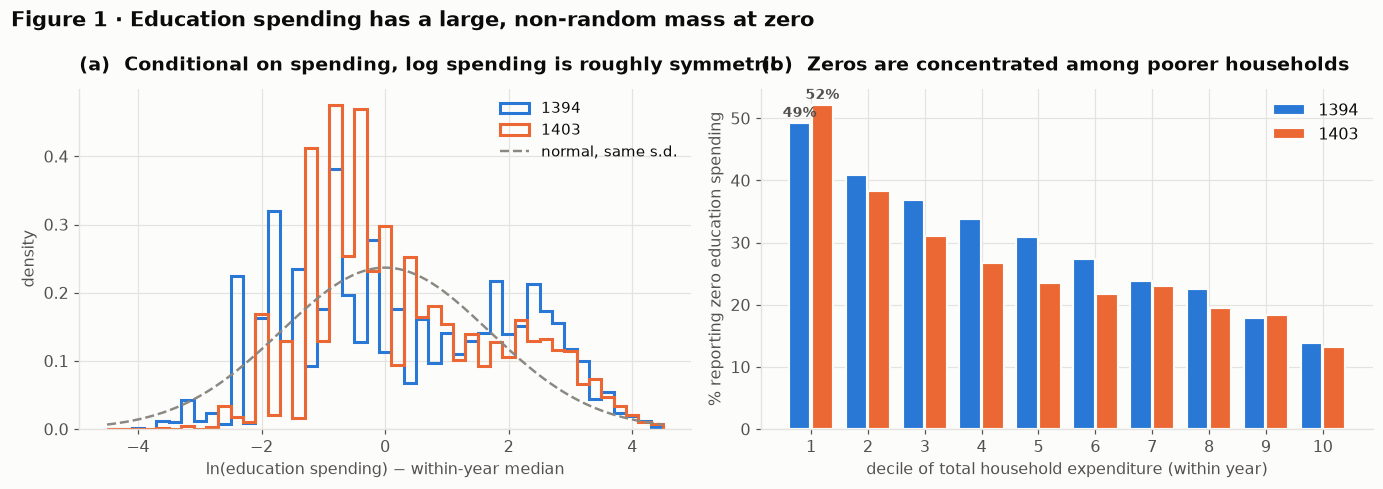

share of at-risk households reporting exactly zero: 28.3%
  bottom expenditure decile: 51%   top decile: 14%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.5))

ax = axes[0]
# centre each wave on its own median so the two SHAPES can be compared without the 12x inflation
med = d[d.pos == 1].groupby("year").ln_edu.transform("median")
cen = (d.loc[d.pos == 1, "ln_edu"] - med)
bins = np.linspace(-4.5, 4.5, 46)
for y in (1394, 1403):
    ax.hist(cen[d.loc[d.pos == 1, "year"] == y], bins=bins, density=True, histtype="step",
            lw=2.0, color=YEARC[y], label=str(y))
xs = np.linspace(-4.5, 4.5, 300)
ax.plot(xs, st.norm.pdf(xs, 0, cen.std()), color=PAL["muted"], lw=1.6, ls="--",
        label="normal, same s.d.")
ax.set_xlabel("ln(education spending) − within-year median")
ax.set_ylabel("density")
ax.set_title("(a)  Conditional on spending, log spending is roughly symmetric", loc="left")
ax.legend(title=None, fontsize=9.5)

ax = axes[1]
dec = d.assign(dec=d.groupby("year").ln_exp.transform(
    lambda s: pd.qcut(s, 10, labels=False) + 1))
g = dec.groupby(["dec", "year"]).pos.mean().unstack() * 100
xs = np.arange(len(g))
wdt = 0.38
for i, y in enumerate((1394, 1403)):
    ax.bar(xs + (i - 0.5) * (wdt + 0.02), 100 - g[y], width=wdt, color=YEARC[y],
           label=str(y), edgecolor=PAL["surface"], linewidth=1.4)
ax.set_xticks(xs, [str(i + 1) for i in range(10)])
ax.set_xlabel("decile of total household expenditure (within year)")
ax.set_ylabel("% reporting zero education spending")
ax.set_title("(b)  Zeros are concentrated among poorer households", loc="left")
ax.legend()
for i, y in enumerate((1394, 1403)):
    ax.annotate(f"{100-g[y].iloc[0]:.0f}%", xy=(xs[0] + (i - .5) * (wdt + .02), 100 - g[y].iloc[0]),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9,
                color=PAL["ink2"], fontweight="semibold")

fig.suptitle("Figure 1 · Education spending has a large, non-random mass at zero",
             x=0.005, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "f01_zeros")
plt.show()

zero_by_dec = (100 - g).round(1)
save_table(zero_by_dec, "t05_zero_share_by_decile")
print(f"share of at-risk households reporting exactly zero: {100*(1-d.pos.mean()):.1f}%")
print(f"  bottom expenditure decile: {(100-g[1394].iloc[0]+100-g[1403].iloc[0])/2:.0f}%   "
      f"top decile: {(100-g[1394].iloc[-1]+100-g[1403].iloc[-1])/2:.0f}%")

The positive log-spending distributions are centred on their own within-year medians. Zero-spending rates are higher in the lowest expenditure deciles. These patterns motivate reporting both conditional positive-spending models and models that retain zeros.

### 4.3 Education budget shares by expenditure rank

The horizontal axis ranks households within each year; it compares relative expenditure positions rather than equal real resource levels. The plotted means are unweighted.

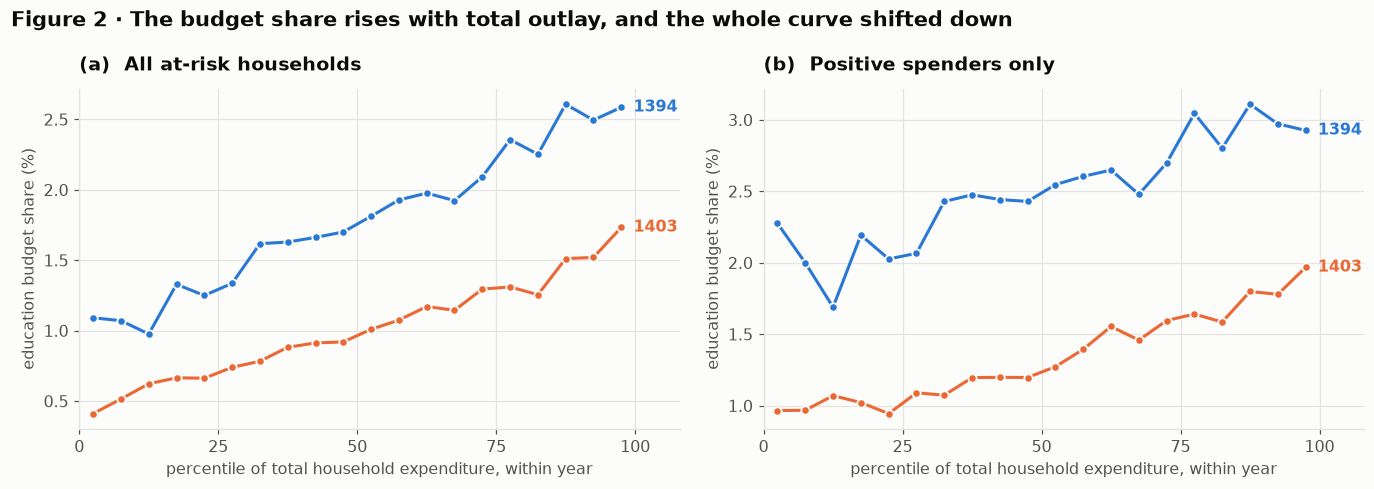

year,1394,1403
pc,,
0,0.0109,0.0041
1,0.0107,0.0052
2,0.0098,0.0062
3,0.0133,0.0066
4,0.0125,0.0066
5,0.0134,0.0074
6,0.0162,0.0078
7,0.0163,0.0088
8,0.0166,0.0091


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.5))
tmp = d.assign(pc=d.groupby("year").ln_exp.transform(lambda s: pd.qcut(s, 20, labels=False)))

for ax, sub, ttl in [
    (axes[0], tmp, "(a)  All at-risk households"),
    (axes[1], tmp[tmp.pos == 1], "(b)  Positive spenders only"),
]:
    gg = sub.groupby(["pc", "year"]).agg(w=("w_edu", "mean")).reset_index()
    gg["x"] = (gg.pc + 0.5) * 5                       # bin midpoint, as a percentile
    for y in (1394, 1403):
        sy = gg[gg.year == y]
        ax.plot(sy.x, sy.w * 100, "o-", color=YEARC[y], label=str(y), markersize=5.5,
                markeredgecolor=PAL["surface"], markeredgewidth=1.2)
        ax.annotate(str(y), xy=(sy.x.iloc[-1], sy.w.iloc[-1] * 100), xytext=(8, 0),
                    textcoords="offset points", color=YEARC[y], fontweight="semibold",
                    fontsize=10.5, va="center")
    ax.set_xlim(0, 108)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("percentile of total household expenditure, within year")
    ax.set_ylabel("education budget share (%)")
    ax.set_title(ttl, loc="left")

fig.suptitle("Figure 2 · The budget share rises with total outlay, and the whole curve shifted down",
             x=0.005, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "f02_engel")
plt.show()
save_table(tmp.groupby(["pc", "year"]).w_edu.mean().unstack().round(5), "t06_engel_curve")

Education budget shares generally rise with expenditure rank. The 1403 curve lies below the 1394 curve in the plotted bins. This describes budget allocation; changes in relative education prices may also affect the shares.

### 4.4 Household groups

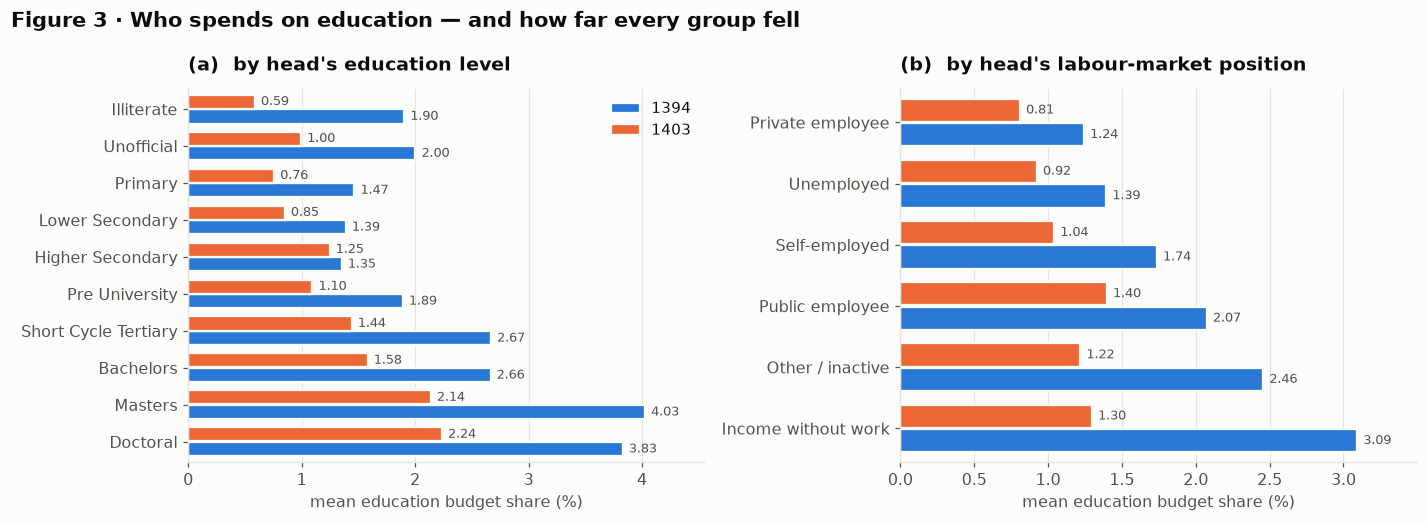

year                                 1394   1403
by education  Illiterate           1.9040 0.5870
              Unofficial           2.0030 0.9950
              Primary              1.4650 0.7570
              Lower_Secondary      1.3890 0.8510
              Higher_Secondary     1.3540 1.2470
              Pre_University       1.8920 1.0950
              Short_Cycle_Tertiary 2.6680 1.4420
              Bachelors            2.6650 1.5820
              Masters              4.0260 2.1380
              Doctoral             3.8300 2.2360
by occupation Private employee     1.2440 0.8100
              Unemployed           1.3940 0.9240
              Self-employed        1.7370 1.0420
              Public employee      2.0750 1.3980
              Other / inactive     2.4570 1.2180
              Income without work  3.0920 1.2970

In [12]:
order_edu = ["Illiterate", "Unofficial", "Primary", "Lower_Secondary", "Higher_Secondary",
             "Pre_University", "Short_Cycle_Tertiary", "Bachelors", "Masters", "Doctoral"]
order_edu = [o for o in order_edu if o in set(d.edulev)]

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
H = 0.38

def grouped_barh(ax, tab, title, ylabels):
    ys = np.arange(len(tab))
    for i, y in enumerate((1394, 1403)):
        ax.barh(ys + (0.5 - i) * (H + 0.02), tab[y] * 100, height=H, color=YEARC[y],
                edgecolor=PAL["surface"], linewidth=1.5, label=str(y))
        for j, v in enumerate(tab[y] * 100):
            ax.annotate(f"{v:.2f}", xy=(v, ys[j] + (0.5 - i) * (H + 0.02)), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=8.5,
                        color=PAL["ink2"])
    ax.set_yticks(ys, ylabels)
    ax.set_ylim(len(tab) - 0.45, -0.55)
    ax.set_xlabel("mean education budget share (%)")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.13)

t_edu = d.pivot_table(index="edulev", columns="year", values="w_edu", aggfunc="mean") \
         .reindex(order_edu)
grouped_barh(axes[0], t_edu, "(a)  by head's education level",
             [o.replace("_", " ") for o in t_edu.index])
axes[0].legend(loc="upper right", fontsize=9.5)

t_occ = d.pivot_table(index="occ", columns="year", values="w_edu", aggfunc="mean") \
         .sort_values(1394)
grouped_barh(axes[1], t_occ, "(b)  by head's labour-market position", list(t_occ.index))

fig.suptitle("Figure 3 · Who spends on education — and how far every group fell",
             x=0.005, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "f03_who_spends")
plt.show()
save_table((pd.concat({"by education": t_edu, "by occupation": t_occ}) * 100).round(3),
           "t06b_shares_by_group")

Shares tend to be higher among households whose heads have tertiary education, but the pattern is not monotone across all education categories. These are unadjusted group comparisons. The regressions use separate category indicators rather than impose a linear education gradient.

## 5. Baseline OLS

We begin with log income, head's education, and employment group (M1). M2 adds year; M3 adds household composition and demographics; M4 adds location, ownership, and season controls. M5 replaces log income with log total expenditure.

The dependent variable is $\ln(\text{education spending})$, so these models use 26,082 positive spenders. Resource coefficients describe conditional elasticities for that subsample. Table standard errors are clustered by province.

In [13]:
BASE   = "C(edulev, Treatment('Illiterate')) + C(occ, Treatment('Private employee'))"
DEMOG  = "ln_stu + kids + fsize + age + age2 + female_head + C(structure, Treatment('Nuclear (2 adults)'))"
STRATA = "urban + owner + C(province) + C(season)"

SPECS = {
    "M1  proposal, pooled":    f"ln_edu ~ ln_inc + {BASE}",
    "M2  + year fixed effect": f"ln_edu ~ ln_inc + {BASE} + C(year)",
    "M3  + demographics":      f"ln_edu ~ ln_inc + {BASE} + C(year) + {DEMOG}",
    "M4  + survey strata":     f"ln_edu ~ ln_inc + {BASE} + C(year) + {DEMOG} + {STRATA}",
    "M5  total exp. instead":  f"ln_edu ~ ln_exp + {BASE} + C(year) + {DEMOG} + {STRATA}",
}

def fit_ols(formula, data, cluster="province"):
    m = smf.ols(formula, data=data)
    return (m.fit(cov_type="HC1"),
            m.fit(cov_type="cluster", cov_kwds={"groups": data.loc[m.data.row_labels, cluster]}))

SHOW = ["ln_inc", "ln_exp", "ln_stu", "kids", "fsize", "age", "age2", "female_head", "urban",
        "owner", "C(edulev, Treatment('Illiterate'))[T.Bachelors]",
        "C(occ, Treatment('Private employee'))[T.Public employee]",
        "C(structure, Treatment('Nuclear (2 adults)'))[T.Single-parent]"]
PRETTY = {
    "ln_inc": "ln(income)", "ln_exp": "ln(total expenditure)", "ln_stu": "ln(enrolled students)",
    "kids": "children < 18", "fsize": "household size", "age": "head's age",
    "age2": "head's age²", "female_head": "female head", "urban": "urban", "owner": "home owner",
    "C(edulev, Treatment('Illiterate'))[T.Bachelors]": "head: Bachelor's  (ref. illiterate)",
    "C(occ, Treatment('Private employee'))[T.Public employee]": "head: public employee  (ref. private)",
    "C(structure, Treatment('Nuclear (2 adults)'))[T.Single-parent]": "single-parent  (ref. nuclear)",
}

def reg_table(specs, data, show=SHOW, pretty=PRETTY, cluster="province", stars=True):
    out, meta = {}, {}
    fits = {}
    for name, f in specs.items():
        rob, clu = fit_ols(f, data, cluster)
        fits[name] = (rob, clu)
        col = {}
        for k in show:
            if k in rob.params.index:
                b, se, p = rob.params[k], clu.bse[k], clu.pvalues[k]
                s = "***" if p < .01 else "**" if p < .05 else "*" if p < .1 else ""
                col[pretty.get(k, k)] = f"{b:.4f}{s if stars else ''}\n({se:.4f})"
            else:
                col[pretty.get(k, k)] = ""
        out[name] = col
        meta[name] = {"N": f"{int(rob.nobs):,}", "R²": f"{rob.rsquared:.3f}",
                      "adj. R²": f"{rob.rsquared_adj:.3f}", "k (params)": f"{int(rob.df_model)+1}"}
    tab = pd.DataFrame(out)
    tab = pd.concat([tab, pd.DataFrame(meta)])
    return tab, fits

t_base, F = reg_table(SPECS, POS)
display(save_table(t_base, "t07_baseline_ols"))
print("Coefficients estimated by OLS on the 26,082 positive spenders. Standard errors in "
      "parentheses are clustered by province (31 clusters).\n*** p<0.01, ** p<0.05, * p<0.1")

# ---- the between-wave slope that M1 is contaminated by ------------------------------------
a, b = POS[POS.year == 1394], POS[POS.year == 1403]
between = np.log(b.edu.median() / a.edu.median()) / np.log(b.income.median() / a.income.median())
print(f"\nmedian income  1394 -> 1403 : x{b.income.median()/a.income.median():5.2f}")
print(f"median edu spend 1394 -> 1403 : x{b.edu.median()/a.edu.median():5.2f}")
print(f"=> implied BETWEEN-wave slope  : {between:.3f}   (vs within-year slope ≈ "
      f"{F['M2  + year fixed effect'][1].params['ln_inc']:.3f} in M2)")

,"M1 proposal, pooled",M2 + year fixed effect,M3 + demographics,M4 + survey strata,M5 total exp. instead
ln(income),0.7713***\n(0.0224),0.9922***\n(0.0579),0.8824***\n(0.0632),0.7532***\n(0.0372),
ln(total expenditure),,,,,0.9104***\n(0.0426)
ln(enrolled students),,,1.0312***\n(0.0411),1.0044***\n(0.0383),0.9371***\n(0.0390)
children < 18,,,0.0778\n(0.0556),0.0589\n(0.0444),0.0722*\n(0.0430)
household size,,,-0.2869***\n(0.0529),-0.2306***\n(0.0423),-0.2263***\n(0.0396)
head's age,,,0.0583***\n(0.0118),0.0575***\n(0.0102),0.0527***\n(0.0097)
head's age²,,,-0.0002\n(0.0001),-0.0002*\n(0.0001),-0.0001\n(0.0001)
female head,,,-0.1190\n(0.0965),-0.1586*\n(0.0946),-0.1843**\n(0.0884)
urban,,,,0.3628***\n(0.0329),0.3342***\n(0.0307)
home owner,,,,-0.1787***\n(0.0275),-0.1380***\n(0.0264)


Coefficients estimated by OLS on the 26,082 positive spenders. Standard errors in parentheses are clustered by province (31 clusters).
*** p<0.01, ** p<0.05, * p<0.1

median income  1394 -> 1403 : x12.41
median edu spend 1394 -> 1403 : x 6.04
=> implied BETWEEN-wave slope  : 0.714   (vs within-year slope ≈ 0.992 in M2)


Adding a year indicator moves the income coefficient from 0.7713 to 0.9922. With the full M4 controls it is 0.7532; M5's expenditure coefficient is 0.9104. M4 explains about 49% of the sample variation in log education spending.

These coefficient changes show sensitivity to controls. They do not establish the size or direction of a causal omitted-variable bias.

## 6. Regression diagnostics

We examine M4's functional form, residual behaviour, standard errors, and collinearity. Exogeneity depends on substantive assumptions and cannot be established by these diagnostics. Province clustering is an approximation rather than a complete survey-design variance estimator.

In [14]:
M4 = smf.ols(SPECS["M4  + survey strata"], data=POS).fit()
M4r = smf.ols(SPECS["M4  + survey strata"], data=POS).fit(cov_type="HC1")
M4c = smf.ols(SPECS["M4  + survey strata"], data=POS).fit(
    cov_type="cluster", cov_kwds={"groups": POS["province"]})
print(f"M4: N = {int(M4.nobs):,}   k = {int(M4.df_model)+1}   R² = {M4.rsquared:.4f}")

M4: N = 26,082   k = 61   R² = 0.4925


### 6.1 Functional form

RESET checks whether powers of the fitted values add explanatory information. A squared log-income specification provides a separate sensitivity check.

In [15]:
rs = linear_reset(M4, power=3, use_f=True)
print(f"RESET (powers 2–3 of ŷ):  F = {rs.statistic:.2f}   p = {rs.pvalue:.4f}")
print(f"=> the null of correct functional form is "
      f"{'REJECTED at 5%' if rs.pvalue < .05 else 'not rejected'}"
      f"{', but NOT at 1%' if rs.pvalue > .01 else ''}")

# is it the Engel curve curvature we saw in Figure 2?
M4q = smf.ols(SPECS["M4  + survey strata"] + " + I(ln_inc**2)", data=POS).fit(
    cov_type="cluster", cov_kwds={"groups": POS["province"]})
print(f"\nadding ln(income)²:  coef = {M4q.params['I(ln_inc ** 2)']:+.4f} "
      f"(se {M4q.bse['I(ln_inc ** 2)']:.4f}, p = {M4q.pvalues['I(ln_inc ** 2)']:.3f}),  "
      f"R² {M4.rsquared:.4f} -> {M4q.rsquared:.4f}")

RESET (powers 2–3 of ŷ):  F = 3.43   p = 0.0324
=> the null of correct functional form is REJECTED at 5%, but NOT at 1%



adding ln(income)²:  coef = +0.0112 (se 0.0110, p = 0.313),  R² 0.4925 -> 0.4926


RESET rejects at 5% (p = 0.0324). The squared log-income term is not significant in the reported check and changes fit little. We retain log-OLS as a baseline while also reporting alternative models.

### 6.2 Standard errors

Compare classical, HC1, and province-clustered estimates of uncertainty.

In [16]:
cmp = pd.DataFrame({
    "coefficient": M4.params[["ln_inc", "ln_stu", "fsize", "urban"]].round(4),
    "SE classical": M4.bse[["ln_inc", "ln_stu", "fsize", "urban"]].round(4),
    "SE robust (HC1)": M4r.bse[["ln_inc", "ln_stu", "fsize", "urban"]].round(4),
    "SE clustered (province)": M4c.bse[["ln_inc", "ln_stu", "fsize", "urban"]].round(4),
})
cmp["cluster / classical"] = (cmp["SE clustered (province)"] / cmp["SE classical"]).round(2)
display(save_table(cmp, "t08_standard_errors"))
print(f"number of clusters: {POS.province.nunique()}  "
      f"(finite-cluster uncertainty remains relevant)")

,coefficient,SE classical,SE robust (HC1),SE clustered (province),cluster / classical
ln_inc,0.7532,0.0202,0.0211,0.0372,1.8400
ln_stu,1.0044,0.0248,0.0254,0.0383,1.5400
fsize,-0.2306,0.0356,0.0437,0.0423,1.1900
urban,0.3628,0.0195,0.0195,0.0329,1.6900


number of clusters: 31  (finite-cluster uncertainty remains relevant)


The province-clustered standard error for the income coefficient is 1.84 times the classical one. With 31 provinces, finite-cluster uncertainty remains relevant; Section 12 includes a wild cluster bootstrap check.

### 6.3 Collinearity

The VIF calculation below covers the listed continuous and indicator regressors, rather than every dummy in the full model. Centring age illustrates how the polynomial's parameterization affects its VIF.

In [17]:
def vif_table(formula, data):
    """VIF must be computed WITH the intercept column in the design matrix."""
    X = patsy.dmatrix(formula, data=data, return_type="dataframe")
    v = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
                  index=X.columns)
    return v.drop("Intercept", errors="ignore").sort_values(ascending=False)

CONT = "ln_inc + ln_stu + kids + fsize + age + age2 + female_head + urban + owner"
P_ctr = POS.assign(age_c=POS.age - POS.age.mean())
P_ctr["age_c2"] = P_ctr.age_c ** 2
CONT_C = CONT.replace("age + age2", "age_c + age_c2")

vif = pd.DataFrame({"VIF, age raw": vif_table(CONT, POS),
                    "VIF, age centred": vif_table(CONT_C, P_ctr).rename(
                        {"age_c": "age", "age_c2": "age2"})})
display(save_table(vif.round(2), "t09_vif"))
sub = vif.drop(index=["age", "age2"], errors="ignore")["VIF, age raw"]
print(f"largest VIF among the substantive regressors: {sub.max():.1f} "
      f"({sub.idxmax()}) — the conventional alarm threshold is 10.")
print(f"age / age² show VIF ≈ {vif.loc['age','VIF, age raw']:.0f} raw but "
      f"{vif.loc['age','VIF, age centred']:.1f} once age is centred: that collinearity is an "
      f"artefact of the polynomial's scale, not a real identification problem.")

,"VIF, age raw","VIF, age centred"
age,45.7700,1.4400
age2,46.0100,1.4500
female_head,1.1900,1.1900
fsize,6.1400,6.1400
kids,6.1000,6.1000
ln_inc,1.0500,1.0500
ln_stu,1.4800,1.4800
owner,1.1200,1.1200
urban,1.0900,1.0900


largest VIF among the substantive regressors: 6.1 (fsize) — the conventional alarm threshold is 10.
age / age² show VIF ≈ 46 raw but 1.4 once age is centred: that collinearity is an artefact of the polynomial's scale, not a real identification problem.


Centring age reduces its VIF from about 45.8 to 1.44 in this diagnostic. Household size and child count have VIFs near six. Reference categories avoid redundant category indicators.

### 6.4 Unobserved household preferences

Education preferences may be associated with both resources and spending. Removing the head's education control illustrates specification sensitivity, but it does not identify the remaining bias or prove its direction.

In [18]:
no_tau = smf.ols(
    SPECS["M4  + survey strata"].replace("C(edulev, Treatment('Illiterate')) + ", ""),
    data=POS).fit(cov_type="cluster", cov_kwds={"groups": POS["province"]})
print(f"elasticity WITHOUT any proxy for taste (head's education dropped) : "
      f"{no_tau.params['ln_inc']:.4f}")
print(f"elasticity WITH  head's education as a proxy (M4)                 : "
      f"{M4c.params['ln_inc']:.4f}")
print(f"\nadding one crude proxy moves the elasticity by "
      f"{M4c.params['ln_inc']-no_tau.params['ln_inc']:+.4f} — in the predicted (downward) "
      f"direction.\nThis comparison does not identify the remaining omitted-variable bias.")

elasticity WITHOUT any proxy for taste (head's education dropped) : 0.8878
elasticity WITH  head's education as a proxy (M4)                 : 0.7532

adding one crude proxy moves the elasticity by -0.1346 — in the predicted (downward) direction.
This comparison does not identify the remaining omitted-variable bias.


The coefficients are interpreted as conditional associations. Income is not randomly assigned, and the later IV specification relies on an additional exclusion assumption.

### 6.5 Heteroskedasticity

In [19]:
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(M4.resid, M4.model.exog)
print(f"Breusch–Pagan:  LM = {bp_lm:,.1f}   p = {bp_p:.3e}")
Xw = patsy.dmatrix("ln_inc + ln_stu + fsize + age + urban", data=POS, return_type="dataframe")
w_lm, w_p, w_f, w_fp = het_white(M4.resid, Xw.values)
print(f"White (subset):  LM = {w_lm:,.1f}   p = {w_p:.3e}")
print("=> homoskedasticity is REJECTED by both tests")

grp = POS.assign(dec=pd.qcut(POS.ln_inc, 10, labels=False)).assign(r2=M4.resid ** 2)
print("\nvariance of the residual by income decile (×1000):")
print((grp.groupby("dec").r2.mean() * 1000).round(1).to_string())

Breusch–Pagan:  LM = 1,661.1   p = 1.043e-307
White (subset):  LM = 1,043.8   p = 2.332e-209
=> homoskedasticity is REJECTED by both tests



variance of the residual by income decile (×1000):
dec
0   1,905.6000
1   2,202.4000
2   2,031.9000
3   2,304.0000
4   2,205.8000
5   1,436.8000
6   1,368.7000
7   1,680.6000
8   1,792.3000
9   1,998.5000


Breusch–Pagan and White tests reject constant residual variance. HC1 and province-clustered covariance estimates address particular forms of inference uncertainty; they do not resolve omitted variables or conditional-mean misspecification.

### 6.6 Residual distribution

Jarque–Bera: 348   p = 2.702e-76    skew = +0.236   excess kurtosis = -0.311


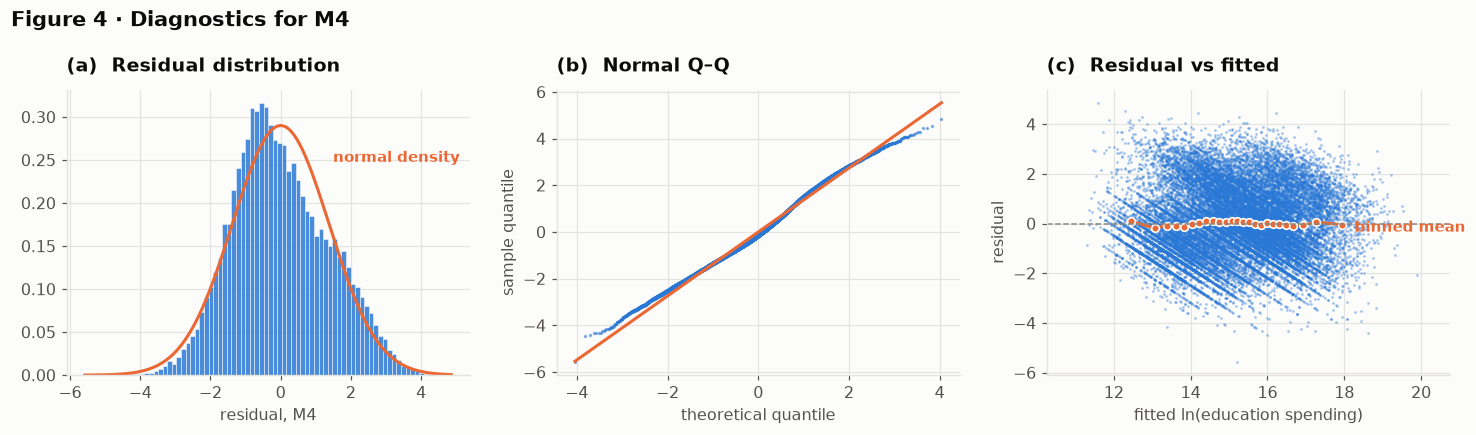

In [20]:
res = M4.resid
jb, jbp = st.jarque_bera(res)[:2]
print(f"Jarque–Bera: {jb:,.0f}   p = {jbp:.3e}    skew = {st.skew(res):+.3f}   "
      f"excess kurtosis = {st.kurtosis(res):+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.0))

ax = axes[0]
ax.hist(res, bins=80, density=True, color=PAL["s1"], alpha=0.85, edgecolor=PAL["surface"], lw=0.4)
xs = np.linspace(res.min(), res.max(), 300)
ax.plot(xs, st.norm.pdf(xs, res.mean(), res.std()), color=PAL["s2"], lw=2.0)
ax.annotate("normal density", xy=(xs[190], st.norm.pdf(xs[190], res.mean(), res.std())),
            xytext=(10, 18), textcoords="offset points", color=PAL["s2"],
            fontsize=9.5, fontweight="semibold")
ax.set_title("(a)  Residual distribution", loc="left")
ax.set_xlabel("residual, M4")

ax = axes[1]
qq = st.probplot(res, dist="norm")
ax.plot(qq[0][0], qq[0][1], ".", color=PAL["s1"], markersize=2.4, alpha=0.5)
lim = [qq[0][0].min(), qq[0][0].max()]
ax.plot(lim, [qq[1][1] + qq[1][0] * l for l in lim], color=PAL["s2"], lw=2.0)
ax.set_title("(b)  Normal Q–Q", loc="left")
ax.set_xlabel("theoretical quantile"); ax.set_ylabel("sample quantile")

ax = axes[2]
ax.plot(M4.fittedvalues, res, ".", color=PAL["s1"], markersize=2.0, alpha=0.28)
bins = pd.qcut(M4.fittedvalues, 25, labels=False)
bm = pd.DataFrame({"f": M4.fittedvalues, "r": res, "b": bins}).groupby("b").mean()
ax.plot(bm.f, bm.r, "o-", color=PAL["s2"], markersize=5,
        markeredgecolor=PAL["surface"], markeredgewidth=1.1)
ax.axhline(0, color=PAL["muted"], lw=1.0, ls="--")
ax.annotate("binned mean", xy=(bm.f.iloc[-1], bm.r.iloc[-1]), xytext=(8, -2),
            textcoords="offset points", color=PAL["s2"], fontsize=9.5, fontweight="semibold",
            ha="left", va="center")
ax.set_xlim(bm.f.iloc[0] - 2.2, bm.f.iloc[-1] + 2.8)
ax.set_title("(c)  Residual vs fitted", loc="left")
ax.set_xlabel("fitted ln(education spending)"); ax.set_ylabel("residual")

fig.suptitle("Figure 4 · Diagnostics for M4", x=0.005, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "f04_diagnostics")
plt.show()

Jarque–Bera rejects normality. The residual plots show the form of the deviations and the relation to fitted spending. Normal errors are not required for OLS consistency under the other regression assumptions; inference here must also account for within-province dependence.

### 6.7 Resource measurement

Income and total expenditure are imperfect measures of resources. Classical measurement error could attenuate a coefficient, but the saved estimates alone cannot establish that mechanism or treat the income coefficient as a lower bound. Section 10 reports an IV comparison with its assumptions.

## 7. Zero spending and the two-part model

There are 10,300 zero spenders in the main sample. Log-OLS describes $E[\ln E\mid X,E>0]$; models including zeros address a different conditional outcome. A reported zero need not mean no schooling or no parental investment.

First, compare a linear probability model and a probit for positive spending. The code uses **probit**. Both include the main controls and province-clustered standard errors. The probit average partial effect is reported alongside its latent-index coefficient.

In [21]:
PART = f"{BASE} + C(year) + {DEMOG} + {STRATA}"

lpm = smf.ols(f"pos ~ ln_inc + {PART}", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d["province"]})
prb = smf.probit(f"pos ~ ln_inc + {PART}", data=d).fit(disp=0, cov_type="cluster",
                                                       cov_kwds={"groups": d["province"]})

# average partial effect of ln(income) on the probability of spending anything
z = prb.fittedvalues
ape = float(np.mean(st.norm.pdf(z)) * prb.params["ln_inc"])
# semi-elasticity  d ln P / d ln income , averaged over the sample
dlnP = float(np.mean(st.norm.pdf(z) / st.norm.cdf(z)) * prb.params["ln_inc"])

part1 = pd.DataFrame({
    "LPM (OLS)":       [f"{lpm.params['ln_inc']:.4f}", f"({lpm.bse['ln_inc']:.4f})",
                        f"{int(lpm.nobs):,}", f"{lpm.rsquared:.3f}", "—"],
    "Probit":          [f"{prb.params['ln_inc']:.4f}", f"({prb.bse['ln_inc']:.4f})",
                        f"{int(prb.nobs):,}", f"{prb.prsquared:.3f}", f"{ape:.4f}"],
}, index=["coefficient on ln(income)", "  cluster SE", "N", "R² / pseudo-R²",
          "average partial effect"])
display(save_table(part1, "t10_participation"))
print(f"LPM predictions outside [0,1]: {int(((lpm.fittedvalues<0)|(lpm.fittedvalues>1)).sum()):,} "
      f"of {int(lpm.nobs):,} ({100*((lpm.fittedvalues<0)|(lpm.fittedvalues>1)).mean():.1f}%) "
      f"— the reason we prefer the probit")
print(f"\nProbit APE: a 10% higher income raises the probability of spending anything by "
      f"{10*ape:.2f} percentage points.")
print(f"Probit semi-elasticity d ln P / d ln(income) = {dlnP:.4f}  <-- the extensive-margin "
      f"elasticity, needed in §7.4")

,LPM (OLS),Probit
coefficient on ln(income),0.0828,0.3269
cluster SE,(0.0118),(0.0395)
N,"36,382","36,382"
R² / pseudo-R²,0.281,0.248
average partial effect,—,0.0821


LPM predictions outside [0,1]: 2,282 of 36,382 (6.3%) — the reason we prefer the probit

Probit APE: a 10% higher income raises the probability of spending anything by 0.82 percentage points.
Probit semi-elasticity d ln P / d ln(income) = 0.1619  <-- the extensive-margin elasticity, needed in §7.4


### 7.4 Combining participation and positive spending

$$E[E\mid X]=P(E>0\mid X)E[E\mid X,E>0].$$

With a common Duan smearing factor for the positive-spending equation, its elasticity does not depend on that factor. The sample-average elasticity is then the log-OLS resource coefficient plus the mean probit participation elasticity. If retransformation varies with resources, that dependence would contribute another term. The estimate below uses the common-factor approximation.

In [22]:
def two_part(data, resource="ln_inc", ctrl=PART, return_parts=False):
    """Return the unconditional resource elasticity from a probit + log-OLS hurdle model."""
    pr = smf.probit(f"pos ~ {resource} + {ctrl}", data=data).fit(disp=0, warn_convergence=False)
    zz = pr.fittedvalues
    ext = float(np.mean(st.norm.pdf(zz) / st.norm.cdf(zz)) * pr.params[resource])
    ols = smf.ols(f"ln_edu ~ {resource} + {ctrl}", data=data[data.pos == 1]).fit()
    inten = float(ols.params[resource])
    if return_parts:
        return ext, inten, float(np.mean(np.exp(ols.resid)))
    return ext + inten

t0 = time.time()
ext, inten, smear = two_part(d, "ln_inc", return_parts=True)
print(f"intensive margin   β_ln(income)          = {inten: .4f}")
print(f"extensive margin   ∂lnP/∂ln(income)      = {ext: .4f}")
print(f"                                          {'-'*10}")
print(f"UNCONDITIONAL income elasticity          = {ext+inten: .4f}")
print(f"\nDuan smearing factor  ŝ = {smear:.4f}  "
      f"(naive exp() would understate predicted spending by {100*(1-1/smear):.1f}%)")
print(f"\nIgnoring the zeros understates the income elasticity by "
      f"{100*ext/(ext+inten):.1f}% of the two-part point estimate.")
print(f"[{time.time()-t0:.1f}s]")

intensive margin   β_ln(income)          =  0.7532
extensive margin   ∂lnP/∂ln(income)      =  0.1619
                                          ----------
UNCONDITIONAL income elasticity          =  0.9151

Duan smearing factor  ŝ = 2.6389  (naive exp() would understate predicted spending by 62.1%)

Ignoring the zeros understates the income elasticity by 17.7% of the two-part point estimate.
[3.6s]


The bootstrap reuses a design matrix and a custom probit solver to reduce repeated fitting time. A minimum-norm linear solve handles redundant columns when a province is absent from a replicate. Before bootstrapping, the solver is compared with `statsmodels` on the full sample.

In [23]:
def solve_psd(A, b, rcond=1e-11):
    """Minimum-norm solution of A x = b for a symmetric PSD A.

    Two details matter here. (i) `lstsq` rather than `solve`: a bootstrap replicate that omits
    the reference province leaves the design rank-deficient, and `solve` would silently return
    garbage rather than raise, sending the Newton iteration below to infinity. (ii) The Jacobi
    (diagonal) preconditioning: our regressors span six orders of magnitude — age² is ~2,500
    while the dummies are 0/1 — so without rescaling, `rcond` would truncate perfectly good
    directions along with the collinear ones."""
    s = np.sqrt(np.abs(np.diag(A)))
    s[s <= 0] = 1.0
    x = np.linalg.lstsq(A / np.outer(s, s), b / s, rcond=rcond)[0]
    return x / s

def ols_fast(X, y):
    return solve_psd(X.T @ X, X.T @ y)


def probit_fit(y, X, b0=None, tol=1e-8, maxit=40):
    """Probit by Newton–Raphson on the normal equations. The k×k system is solved with a
    pseudo-inverse fallback, so a rank-deficient design returns the minimum-norm solution
    instead of blowing up — and each step costs O(n k²) rather than a full SVD."""
    b = np.zeros(X.shape[1]) if b0 is None else np.asarray(b0, float).copy()
    q = 2.0 * y - 1.0
    for _ in range(maxit):
        xb = X @ b
        qxb = q * xb
        lam = q * np.exp(st.norm.logpdf(qxb) - np.clip(st.norm.logcdf(qxb), -700, None))
        w = np.clip(lam * (lam + xb), 1e-12, None)
        step = solve_psd((X * w[:, None]).T @ X, X.T @ lam)
        b = b + step
        if np.max(np.abs(step)) < tol:
            break
    return b

# ---------------- SELF-TEST 4: our probit == statsmodels' probit ----------------
_yc_ = d.pos.to_numpy(float)
_Xc_ = patsy.dmatrix(f"ln_inc + {PART}", data=d, return_type="dataframe")
_b_mine = probit_fit(_yc_, _Xc_.to_numpy())
_b_sm = sm.Probit(_yc_, _Xc_.to_numpy()).fit(disp=0).params
assert np.max(np.abs(_b_mine - _b_sm)) < 1e-6, "hand-written probit disagrees with statsmodels"
print(f"self-test 4 PASSED  max|mine - statsmodels| = {np.abs(_b_mine-_b_sm).max():.2e} "
      f"over {len(_b_mine)} probit coefficients")

self-test 4 PASSED  max|mine - statsmodels| = 2.66e-14 over 61 probit coefficients


In [24]:
y_pos_a = d.pos.to_numpy(float)
X_a = _Xc_.to_numpy()
jres_a = list(_Xc_.columns).index("ln_inc")
ln_y_a = d.ln_edu.to_numpy()
b_full = _b_mine

def two_part_fast(idx):
    """Unconditional elasticity from probit + log-OLS on a row subset `idx`."""
    Xi, yi, li = X_a[idx], y_pos_a[idx], ln_y_a[idx]
    bb = probit_fit(yi, Xi, b0=b_full)                       # warm start: 3–4 Newton steps
    zz = Xi @ bb
    ext_ = float(np.mean(np.exp(st.norm.logpdf(zz) - st.norm.logcdf(zz))) * bb[jres_a])
    m = yi == 1
    b_ = ols_fast(Xi[m], li[m])
    return ext_ + float(b_[jres_a])

eta_inc = ext + inten
chk = two_part_fast(np.arange(len(d)))
print(f"fast estimator on the full sample: {chk:.6f}   vs the §7.4 result {eta_inc:.6f}   "
      f"(difference {abs(chk-eta_inc):.2e})")
assert abs(chk - eta_inc) < 1e-6, "fast path does not reproduce the formula-based estimate"

prov_arr = d.province.to_numpy()
prov_rows = {p: np.flatnonzero(prov_arr == p) for p in np.unique(prov_arr)}
provs = np.array(list(prov_rows))

B = 300
t0 = time.time()
boot = []
for _ in range(B):
    draw = rng.choice(provs, size=len(provs), replace=True)
    idx = np.concatenate([prov_rows[p] for p in draw])
    try:
        boot.append(two_part_fast(idx))
    except Exception:
        boot.append(np.nan)
boot = np.array(boot, float)
boot = boot[np.isfinite(boot)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nprovince block bootstrap, B = {len(boot)} successful replicates  [{time.time()-t0:.0f}s]")
print(f"unconditional income elasticity = {eta_inc:.4f}   "
      f"95% CI [{lo:.4f}, {hi:.4f}]   bootstrap SE {boot.std(ddof=1):.4f}")
save_table(pd.DataFrame({"bootstrap replicate": boot}), "t11_bootstrap_replicates")

fast estimator on the full sample: 0.915116   vs the §7.4 result 0.915116   (difference 4.56e-12)



province block bootstrap, B = 300 successful replicates  [40s]
unconditional income elasticity = 0.9151   95% CI [0.8247, 1.0235]   bootstrap SE 0.0556


,bootstrap replicate
0,0.9329
1,0.8942
2,0.9048
3,0.9203
4,0.9217
...,...
295,0.9035
296,0.8835
297,0.9933
298,0.8831


### 7.5 Interpretation

The income estimate is 0.7532 + 0.1619 = 0.9151. Its 300-replicate province-bootstrap 95% interval is [0.8247, 1.0235], including one. This combines the two margins under the specified model; it is not an identified causal response.

### 7.6 Selection diagnostic

An inverse Mills ratio is added as a sensitivity check. There is no separate exclusion variable for participation, so identification comes from functional form. This is not the main specification. The two-part factorization itself does not require independence between latent errors in two structural decisions.

In [25]:
mills_z = prb.fittedvalues
d_h = d.assign(imr=st.norm.pdf(mills_z) / st.norm.cdf(mills_z))
heck = smf.ols(f"ln_edu ~ ln_inc + {PART} + imr", data=d_h[d_h.pos == 1]).fit(
    cov_type="cluster", cov_kwds={"groups": d_h.loc[d_h.pos == 1, "province"]})
sig_u = np.sqrt(heck.mse_resid + heck.params["imr"] ** 2 * np.mean(
    d_h.loc[d_h.pos == 1, "imr"] * (d_h.loc[d_h.pos == 1, "imr"] + mills_z[d_h.pos == 1])))
rho = heck.params["imr"] / sig_u
print(f"inverse Mills ratio coefficient = {heck.params['imr']:+.4f} "
      f"(cluster SE {heck.bse['imr']:.4f}, p = {heck.pvalues['imr']:.4f})")
print(f"implied ρ ≈ {rho:+.3f}")
print(f"income elasticity, intensive margin:  log-OLS {inten:.4f}  ->  Heckman-corrected "
      f"{heck.params['ln_inc']:.4f}")
print("\nIdentified off functional form only — reported as a diagnostic, not as a preferred "
      "estimate (see §7.6).")

inverse Mills ratio coefficient = +0.7118 (cluster SE 0.3340, p = 0.0331)
implied ρ ≈ +0.493
income elasticity, intensive margin:  log-OLS 0.7532  ->  Heckman-corrected 0.8389

Identified off functional form only — reported as a diagnostic, not as a preferred estimate (see §7.6).


## 8. Tobit and PPML

### 8.1 Tobit on the budget share

The Tobit uses $w=\max(0,X\beta+u)$ with a normal, constant-variance latent error. We fit the share in percentage points and convert the mean observed-share derivative into an elasticity evaluated using the mean share. Tobit imposes stronger distributional restrictions and ignores the share's upper bound of one. It is an additional specification rather than proof that observed zeros are censoring.

The custom implementation is checked on synthetic data with and without censoring.

In [26]:
def tobit_ll(theta, y, X, left=0.0):
    """Negative log-likelihood of the left-censored Tobit, with analytic gradient."""
    b, ls = theta[:-1], theta[-1]
    s = np.exp(ls)
    xb = X @ b
    unc = y > left
    z = (y - xb) / s
    zc = (left - xb) / s
    ll = np.where(unc, -np.log(s) + st.norm.logpdf(z), st.norm.logcdf(zc))
    lam = st.norm.pdf(zc) / np.clip(st.norm.cdf(zc), 1e-300, None)
    g_b = X.T @ np.where(unc, z / s, -lam / s)
    g_ls = np.sum(np.where(unc, z ** 2 - 1.0, -lam * zc))
    return -ll.sum(), -np.append(g_b, g_ls)

def tobit(y, X, left=0.0):
    """Left-censored Tobit by ML. Returns (beta, sigma, result).

    The columns are internally rescaled to unit standard deviation before the optimiser sees
    them. This is exact — if x̃ⱼ = xⱼ/sⱼ then β̃ⱼ = βⱼ·sⱼ and the likelihood is unchanged — but it
    matters enormously in practice: our design mixes age² (~2,500) with 0/1 dummies, and
    quasi-Newton methods stall on that kind of conditioning."""
    s = X.std(axis=0)
    s[s == 0] = 1.0                              # leave the intercept alone
    Xs = X / s
    ols = np.linalg.lstsq(Xs, y, rcond=None)[0]
    th0 = np.append(ols, np.log(max(np.std(y - Xs @ ols), 1e-8)))
    r = optimize.minimize(tobit_ll, th0, args=(y, Xs, left), jac=True, method="L-BFGS-B",
                          options={"maxiter": 5000, "maxfun": 20000,
                                   "ftol": 1e-15, "gtol": 1e-9})
    return r.x[:-1] / s, float(np.exp(r.x[-1])), r

# ---------------- SELF-TEST 1: no censoring binds  =>  Tobit must equal OLS ----------------
_rg = np.random.default_rng(7)
_X = np.column_stack([np.ones(4000), _rg.normal(size=4000), _rg.normal(size=4000)])
_b = np.array([5.0, 1.5, -0.8])
_y = _X @ _b + _rg.normal(scale=1.0, size=4000)
_bt, _st_, _ = tobit(_y, _X, left=_y.min() - 10)          # censoring point binds on nobody
_bo = np.linalg.lstsq(_X, _y, rcond=None)[0]
assert np.allclose(_bt, _bo, atol=1e-4), f"Tobit != OLS without censoring: {_bt} vs {_bo}"
print(f"self-test 1 PASSED  max|Tobit - OLS| = {np.abs(_bt-_bo).max():.2e} when nothing is censored")

# ---------------- SELF-TEST 2: heavy censoring  =>  Tobit must beat OLS ----------------
_yc = np.maximum(_y - 5.0, 0.0)                            # ~50% censored at zero
_bt2, _s2, _ = tobit(_yc, _X, left=0.0)
_bo2 = np.linalg.lstsq(_X, _yc, rcond=None)[0]
_true = _b.copy(); _true[0] -= 5.0
err_tobit = np.abs(_bt2[1:] - _true[1:]).mean()
err_ols = np.abs(_bo2[1:] - _true[1:]).mean()
assert err_tobit < err_ols, "Tobit failed to beat OLS under censoring"
print(f"self-test 2 PASSED  censoring rate {100*(_yc==0).mean():.0f}% | "
      f"mean |error|: Tobit {err_tobit:.4f} vs OLS {err_ols:.4f} "
      f"({100*(1-err_tobit/err_ols):.0f}% better)")

self-test 1 PASSED  max|Tobit - OLS| = 1.33e-15 when nothing is censored
self-test 2 PASSED  censoring rate 51% | mean |error|: Tobit 0.0291 vs OLS 0.5717 (95% better)


In [27]:
t0 = time.time()
# the share is expressed in PERCENTAGE POINTS so that sigma is O(1) rather than O(0.03)
yv, Xv = patsy.dmatrices(f"I(w_edu*100) ~ ln_exp + {PART}", data=d, return_type="dataframe")
bt, sg, res_t = tobit(yv.values.ravel(), Xv.values, left=0.0)
tb = pd.Series(bt, index=Xv.columns)
scale = float(np.mean(st.norm.cdf((Xv.values @ bt) / sg)))       # McDonald–Moffitt factor
wbar = float(d.w_edu.mean())
eta_tobit = 1 + scale * (tb["ln_exp"] / 100) / wbar              # undo the ×100 on the share
print(f"Tobit: converged = {res_t.success}   ({time.time()-t0:.0f}s, {res_t.nit} iterations, "
      f"max|gradient| = {np.max(np.abs(res_t.jac)):.2e})")
assert res_t.success, "Tobit MLE failed to converge — do not report this estimate"
print(f"  censored observations : {int((d.w_edu==0).sum()):,} of {len(d):,} "
      f"({100*(d.w_edu==0).mean():.1f}%)")
print(f"  latent β on ln(total expenditure) : {tb['ln_exp']:+.5f} pp   σ = {sg:.4f} pp")
print(f"  McDonald–Moffitt scaling Φ(·)     : {scale:.4f}")
print(f"  => implied expenditure elasticity : {eta_tobit:.4f}")

Tobit: converged = True   (23s, 654 iterations, max|gradient| = 7.20e-03)
  censored observations : 10,300 of 36,382 (28.3%)
  latent β on ln(total expenditure) : +0.62199 pp   σ = 3.4318 pp
  McDonald–Moffitt scaling Φ(·)     : 0.5578
  => implied expenditure elasticity : 1.2451


### 8.2 PPML

PPML fits an exponential conditional mean to spending levels, retaining zeros. Spending need not be an integer count for this quasi-likelihood use. Consistency still requires the conditional mean and exogeneity assumptions. The resource coefficient is the elasticity under the specified mean function.

In [28]:
t0 = time.time()
yg, Xg = patsy.dmatrices(f"edu ~ ln_exp + {PART}", data=d, return_type="dataframe")
ppml = sm.GLM(yg / 1e6, Xg, family=sm.families.Poisson()).fit(
    cov_type="cluster", cov_kwds={"groups": d.loc[Xg.index, "province"]})
eta_ppml = float(ppml.params["ln_exp"])
print(f"PPML (expenditure): elasticity = {eta_ppml:.4f}  (cluster SE {ppml.bse['ln_exp']:.4f})"
      f"   [{time.time()-t0:.0f}s]")

yg2, Xg2 = patsy.dmatrices(f"edu ~ ln_inc + {PART}", data=d, return_type="dataframe")
ppml_i = sm.GLM(yg2 / 1e6, Xg2, family=sm.families.Poisson()).fit(
    cov_type="cluster", cov_kwds={"groups": d.loc[Xg2.index, "province"]})
eta_ppml_inc = float(ppml_i.params["ln_inc"])
print(f"PPML (income)     : elasticity = {eta_ppml_inc:.4f}  "
      f"(cluster SE {ppml_i.bse['ln_inc']:.4f})")
print(f"\nfor comparison, two-part model with the same income regressor: {eta_inc:.4f}")

PPML (expenditure): elasticity = 1.0389  (cluster SE 0.0712)   [3s]


PPML (income)     : elasticity = 0.9035  (cluster SE 0.0780)

for comparison, two-part model with the same income regressor: 0.9151


### 8.3 Comparison

The income PPML estimate is 0.9035, close to the income two-part estimate of 0.9151. Expenditure-based PPML and two-part estimates are 1.0389 and 1.1191. The methods differ in their conditional-mean and retransformation assumptions.

## 9. Spending per student

For positive spenders, regress total log spending and log spending per enrolled student on the same regressors. The student-count coefficients satisfy

$$\delta_{ps}=\delta_{total}-1.$$

A negative per-student coefficient is consistent with resources being spread across more students. It does not identify education quality, allocation between children, or the causal effect of family size.

In [29]:
QQ = f"{BASE} + C(year) + kids + fsize + age + age2 + female_head + " \
     f"C(structure, Treatment('Nuclear (2 adults)')) + {STRATA}"

rows = []
for lab, R in [("reported income", "ln_inc"), ("total expenditure", "ln_exp")]:
    tot = smf.ols(f"ln_edu ~ {R} + ln_stu + {QQ}", data=POS).fit(
        cov_type="cluster", cov_kwds={"groups": POS["province"]})
    ps = smf.ols(f"ln_edu_ps ~ {R} + ln_stu + {QQ}", data=POS).fit(
        cov_type="cluster", cov_kwds={"groups": POS["province"]})
    tst = tot.t_test("ln_stu = 1")
    rows.append({
        "resource control": lab,
        "δ_tot  (total spending)": f"{tot.params['ln_stu']:.4f} ({tot.bse['ln_stu']:.4f})",
        "δ_ps  (per student)": f"{ps.params['ln_stu']:+.4f} ({ps.bse['ln_stu']:.4f})",
        "p, H₀: δ_tot = 1": f"{float(np.squeeze(tst.pvalue)):.4f}",
        "verdict": ("trade-off (p<0.05)" if ps.pvalues["ln_stu"] < .05 and ps.params["ln_stu"] < 0
                    else f"negative but n.s. (p={ps.pvalues['ln_stu']:.2f})"
                    if ps.params["ln_stu"] < 0 else "no trade-off"),
    })
qq = pd.DataFrame(rows).set_index("resource control")
display(save_table(qq, "t12_quantity_quality"))
print("Cluster-robust SEs in parentheses. δ_ps = δ_tot − 1 by construction, so the two columns "
      "carry\nthe same information — both are shown because they answer different questions.")

,δ_tot (total spending),δ_ps (per student),"p, H₀: δ_tot = 1",verdict
resource control,,,,
reported income,1.0044 (0.0383),+0.0044 (0.0383),0.9081,no trade-off
total expenditure,0.9371 (0.0390),-0.0629 (0.0390),0.1066,negative but n.s. (p=0.11)


Cluster-robust SEs in parentheses. δ_ps = δ_tot − 1 by construction, so the two columns carry
the same information — both are shown because they answer different questions.


The expenditure-controlled per-student coefficient is −0.0629 (p = 0.1066); the income-controlled estimate is 0.0044 (p = 0.9081). Neither rejects zero at 5% using province clustering.

### 9.2 Estimates by expenditure tercile

Terciles are formed within each year among positive spenders. These subgroup regressions explore whether the pooled pattern masks different associations.

,δ_ps,cluster SE,p,N
tercile of total expenditure,,,,
bottom third,-0.1372,0.0563,0.0148,8695
middle third,-0.0174,0.0554,0.7536,8693
top third,-0.0426,0.0483,0.3781,8694


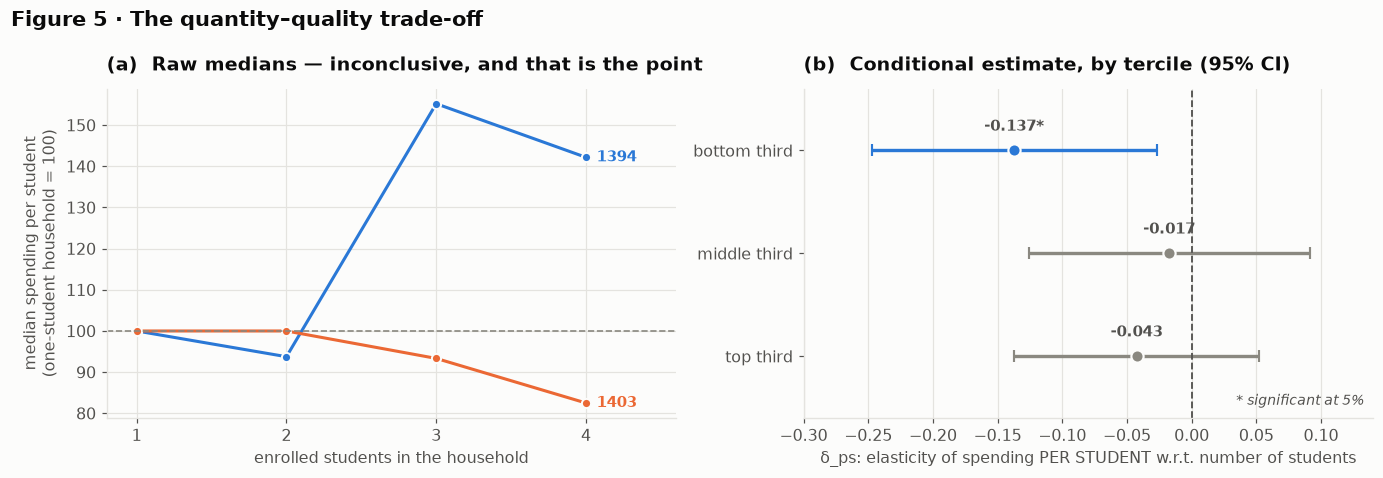

In [30]:
POS2 = POS.assign(terc=POS.groupby("year").ln_exp.transform(
    lambda s: pd.qcut(s, 3, labels=["bottom third", "middle third", "top third"])))
rows = []
for t, g in POS2.groupby("terc", observed=True):
    m = smf.ols(f"ln_edu_ps ~ ln_exp + ln_stu + {QQ}", data=g).fit(
        cov_type="cluster", cov_kwds={"groups": g["province"]})
    rows.append({"tercile of total expenditure": t, "δ_ps": m.params["ln_stu"],
                 "cluster SE": m.bse["ln_stu"], "p": m.pvalues["ln_stu"], "N": int(m.nobs)})
qt = pd.DataFrame(rows).set_index("tercile of total expenditure")
display(save_table(qt.round(4), "t13_qq_by_tercile"))

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4))

ax = axes[0]
# median of the RATIO (not ratio of medians), indexed within each wave so inflation cannot enter
POSps = POS.assign(ps=POS.edu / POS.students)
for y in (1394, 1403):
    gy = POSps[POSps.year == y].groupby("students").agg(m=("ps", "median"), n=("ps", "size"))
    gy = gy[gy.n >= 100]
    idx = 100 * gy.m / gy.m.iloc[0]
    ax.plot(gy.index, idx, "o-", color=YEARC[y], label=str(y),
            markeredgecolor=PAL["surface"], markeredgewidth=1.3)
    ax.annotate(str(y), xy=(gy.index[-1], idx.iloc[-1]), xytext=(7, 0),
                textcoords="offset points", color=YEARC[y], fontweight="semibold",
                fontsize=10, va="center")
ax.axhline(100, color=PAL["muted"], lw=1.1, ls="--")
ax.set_xlabel("enrolled students in the household")
ax.set_ylabel("median spending per student\n(one-student household = 100)")
ax.set_title("(a)  Unadjusted median spending per student", loc="left")
ax.set_xticks([1, 2, 3, 4])
ax.set_xlim(0.8, 4.6)

ax = axes[1]
ys = np.arange(len(qt))
sig = qt["p"] < 0.05
for i, (v, se, sg) in enumerate(zip(qt["δ_ps"], qt["cluster SE"], sig)):
    col = PAL["s1"] if sg else PAL["muted"]
    ax.errorbar(v, i, xerr=1.96 * se, fmt="o", color=col, ecolor=col, elinewidth=2.2,
                capsize=4, markersize=8, markeredgecolor=PAL["surface"], markeredgewidth=1.4)
    ax.annotate(f"{v:+.3f}" + ("*" if sg else ""), xy=(v, i), xytext=(0, 13),
                textcoords="offset points", ha="center", fontsize=9.5,
                color=PAL["ink2"], fontweight="semibold")
ax.axvline(0, color=PAL["ink2"], lw=1.2, ls="--")
ax.set_yticks(ys, qt.index)
ax.set_ylim(len(qt) - 0.4, -0.6)
ax.set_xlim(-0.30, 0.14)
ax.set_xlabel("δ_ps: elasticity of spending PER STUDENT w.r.t. number of students")
ax.set_title("(b)  Conditional estimate, by tercile (95% CI)", loc="left")
ax.annotate("* significant at 5%", xy=(0.985, 0.04), xycoords="axes fraction", ha="right",
            fontsize=9, color=PAL["ink2"], style="italic")
ax.grid(axis="y", visible=False)

fig.suptitle("Figure 5 · The quantity–quality trade-off", x=0.005, ha="left",
             fontsize=13.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "f05_quantity_quality")
plt.show()

### 9.3 Subgroup interpretation

The bottom-third per-student coefficient is −0.1372 (p = 0.0148), compared with −0.0174 and −0.0426 in the middle and top thirds. Separate significance tests do not establish differences between groups. The pattern is consistent with budget constraints, but it does not identify that mechanism.

The raw median comparison is unadjusted; the subgroup regressions condition on the specified resource and household controls.

## 10. Resource measures and 2SLS

The Working–Leser equation regresses the education share on log total expenditure and controls. Total expenditure appears in both the share denominator and the regressor, making correlated measurement error a concern.

We instrument log total expenditure with log income. The required exclusion restriction is that income has no separate association with the share-equation error after conditioning on the controls. Relevance can be assessed in the first stage, but exclusion cannot be verified by a strong first stage or a Durbin–Wu–Hausman test.

The custom 2SLS implementation is checked against `statsmodels` on synthetic data. Its covariance uses HC0 without province clustering. The first-stage and control-function fits below use province-clustered standard errors.

In [31]:
def tsls(y, X, Z):
    """2SLS by hand.  X = regressors (endogenous first is fine), Z = instruments (same k)."""
    ZtZ_inv_Zt = np.linalg.solve(Z.T @ Z, Z.T)
    Xhat = Z @ (ZtZ_inv_Zt @ X)
    b = np.linalg.solve(Xhat.T @ X, Xhat.T @ y)
    u = y - X @ b
    n, k = X.shape
    # heteroskedasticity-robust (HC0) 2SLS variance
    bread = np.linalg.inv(Xhat.T @ X)
    meat = (Xhat * u[:, None]).T @ (Xhat * u[:, None])
    V = bread @ meat @ bread.T
    return b, np.sqrt(np.diag(V)), u

# ---------------- SELF-TEST 3: reproduce statsmodels' IV2SLS exactly ----------------
from statsmodels.sandbox.regression.gmm import IV2SLS as _SM_IV2SLS
_rg = np.random.default_rng(11)
_n = 3000
_z = _rg.normal(size=_n); _e = _rg.normal(size=_n)
_x = 0.8 * _z + 0.6 * _e + _rg.normal(size=_n)          # endogenous by construction
_y = 1.0 + 2.0 * _x + _e
_Xm = np.column_stack([np.ones(_n), _x])
_Zm = np.column_stack([np.ones(_n), _z])
_b_mine, _, _ = tsls(_y, _Xm, _Zm)
_b_sm = _SM_IV2SLS(_y, _Xm, _Zm).fit().params
assert np.allclose(_b_mine, _b_sm, atol=1e-10), f"2SLS mismatch: {_b_mine} vs {_b_sm}"
_b_ols = np.linalg.lstsq(_Xm, _y, rcond=None)[0]
print(f"self-test 3 PASSED  max|mine - statsmodels| = {np.abs(_b_mine-_b_sm).max():.2e}")
print(f"  (on this synthetic design the true slope is 2.000: "
      f"OLS gives {_b_ols[1]:.3f}, 2SLS gives {_b_mine[1]:.3f})")

self-test 3 PASSED  max|mine - statsmodels| = 4.44e-16
  (on this synthetic design the true slope is 2.000: OLS gives 2.290, 2SLS gives 1.998)


In [32]:
WL = f"w_edu ~ ln_exp + {PART}"
yv, Xv = patsy.dmatrices(WL, data=d, return_type="dataframe")
Zv = Xv.copy()
Zv["ln_exp"] = d.loc[Xv.index, "ln_inc"].to_numpy()          # swap in the instrument
j = list(Xv.columns).index("ln_exp")
y_, X_, Z_ = yv.to_numpy().ravel(), Xv.to_numpy(), Zv.to_numpy()

wl_ols = smf.ols(WL, data=d).fit(cov_type="cluster", cov_kwds={"groups": d["province"]})
b_iv, se_iv, u_iv = tsls(y_, X_, Z_)

fs = smf.ols(f"ln_exp ~ ln_inc + {PART}", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d["province"]})
print(f"FIRST STAGE   ln(total expenditure) on ln(income)")
print(f"  coefficient {fs.params['ln_inc']:.4f} (cluster SE {fs.bse['ln_inc']:.4f})   "
      f"robust F = {fs.tvalues['ln_inc']**2:,.0f}   R² = {fs.rsquared:.3f}")
print(f"  => the first stage shows strong relevance; exclusion remains an assumption.\n")

wbar = float(d.w_edu.mean())
eta_wl_ols = 1 + wl_ols.params["ln_exp"] / wbar
eta_wl_iv = 1 + b_iv[j] / wbar
print(f"WORKING–LESER, mean budget share w̄ = {wbar:.5f}")
print(f"  OLS   β = {wl_ols.params['ln_exp']:+.6f} ({wl_ols.bse['ln_exp']:.6f})"
      f"   =>  η = 1 + β/w̄ = {eta_wl_ols:.4f}")
print(f"  2SLS  β = {b_iv[j]:+.6f} ({se_iv[j]:.6f})"
      f"   =>  η = 1 + β/w̄ = {eta_wl_iv:.4f}")

# ---- Durbin–Wu–Hausman: is ln(total expenditure) endogenous in this equation? --------------
d_dwh = d.copy()
d_dwh["v_hat"] = fs.resid
dwh = smf.ols(WL + " + v_hat", data=d_dwh).fit(
    cov_type="cluster", cov_kwds={"groups": d_dwh["province"]})
print(f"\nDURBIN–WU–HAUSMAN (control-function form)")
print(f"  coefficient on the first-stage residual = {dwh.params['v_hat']:+.6f} "
      f"(cluster SE {dwh.bse['v_hat']:.6f}),  p = {dwh.pvalues['v_hat']:.3e}")
print(f"  => H₀ (ln total expenditure is exogenous) is "
      f"{'REJECTED' if dwh.pvalues['v_hat'] < .05 else 'not rejected'}; the OLS/2SLS gap is "
      f"systematic, not sampling noise.")

FIRST STAGE   ln(total expenditure) on ln(income)
  coefficient 0.6309 (cluster SE 0.0154)   robust F = 1,670   R² = 0.921
  => the first stage shows strong relevance; exclusion remains an assumption.

WORKING–LESER, mean budget share w̄ = 0.01415
  OLS   β = +0.002507 (0.000491)   =>  η = 1 + β/w̄ = 1.1771
  2SLS  β = +0.005383 (0.000576)   =>  η = 1 + β/w̄ = 1.3803



DURBIN–WU–HAUSMAN (control-function form)
  coefficient on the first-stage residual = -0.004480 (cluster SE 0.000924),  p = 1.237e-06
  => H₀ (ln total expenditure is exogenous) is REJECTED; interpret this diagnostic conditional on instrument validity.


### 10.3 Model comparison

The table groups nine point estimates by resource measure and specification. The threshold labels refer only to whether a point estimate is above or below one; they do not test that threshold. The estimates are not all measurements of an identical estimand.

elasticity η                         specification           note luxury / necessity
resource measure  estimator                                                                                                                     
reported income   log-OLS, positive spenders only (§5, M4)        0.7532      positive-spending subsample    conditional log-spending slope          necessity
                  two-part model (§7.4)                           0.9151                         includes zeros   ↑ vs log-OLS          necessity
                  PPML (§8.2)                                     0.9035    includes zeros, no retransformation     ≈ two-part          necessity
total expenditure log-OLS, positive spenders only (§5, M5)        0.9104  positive-spending subsample    ↑ vs income          necessity
                  two-part model                                  1.1191          includes zeros; expenditure regressor        ↑ again             luxury
                  PPML (§8.2)                                     1.0389   includes zeros, mean-only assumption     ≈ two-part             luxury
                  Tobit on the budget share (§8.1)                1.2451                    zeros as censoring    cross-check             luxury
                  Working–Leser OLS (§10.2)                       1.1771           share equation; expenditure regressor    OLS specification             luxury
                  Working–Leser 2SLS (§10.2)                      1.3803            share form, X instrumented  depends on income exclusion             luxury

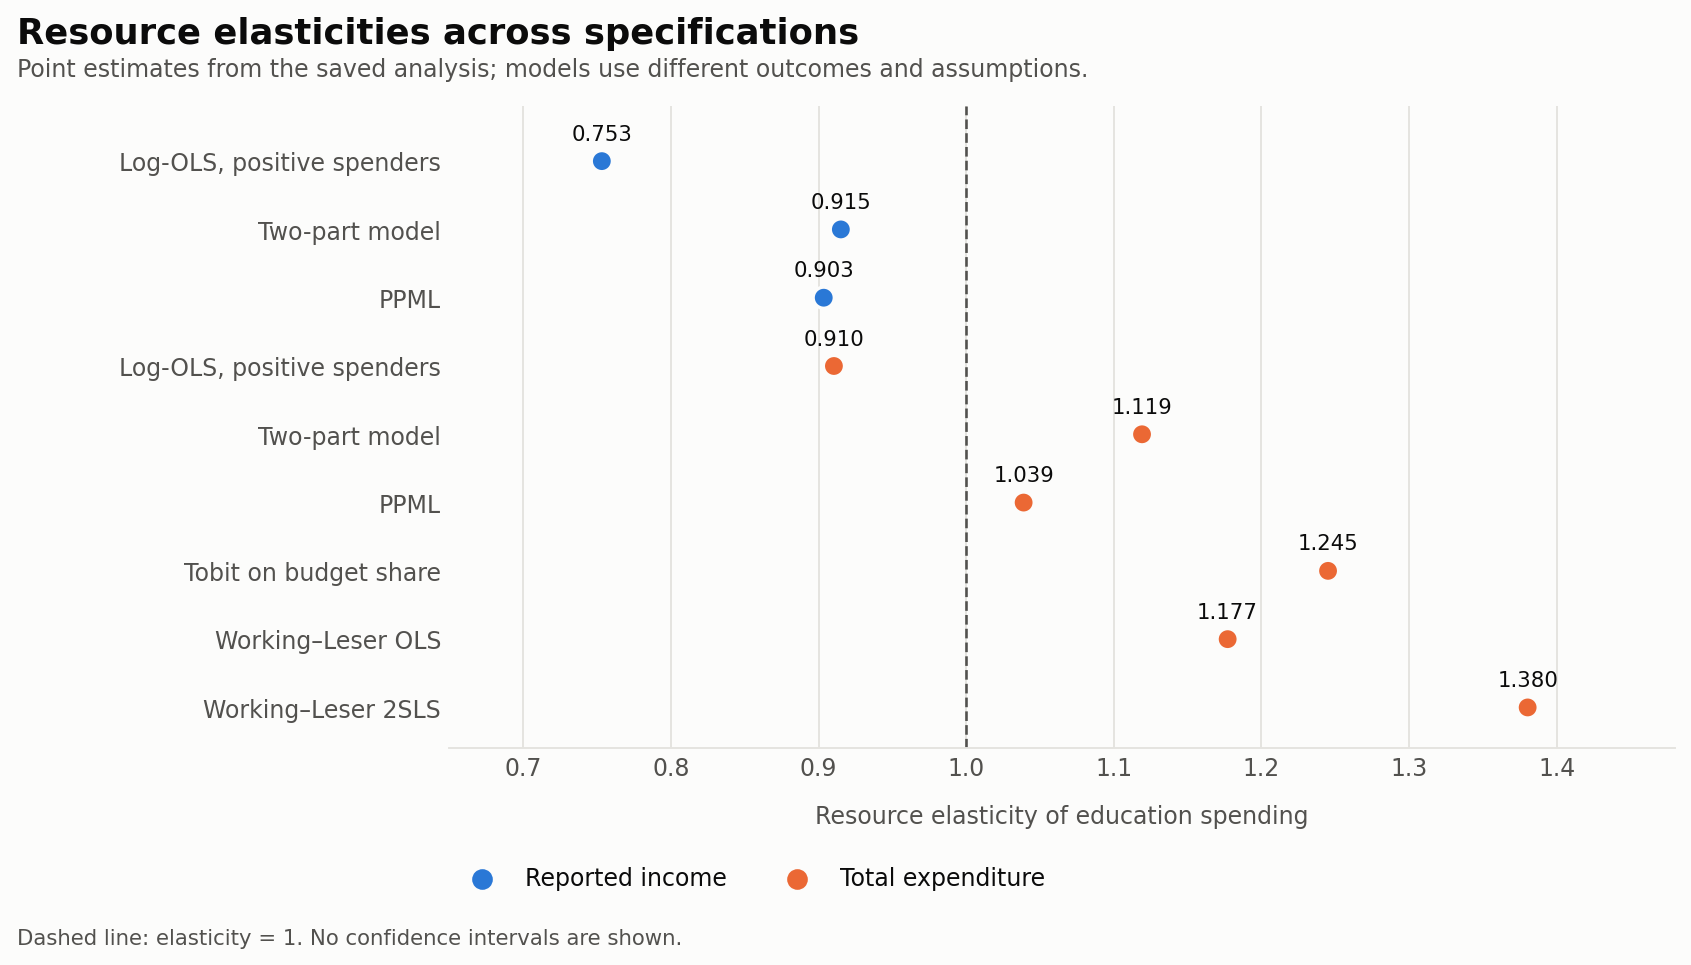

In [33]:
inten_exp = float(smf.ols(f"ln_edu ~ ln_exp + {PART}", data=POS).fit().params["ln_exp"])
ext_exp, inten_exp2, _ = two_part(d, "ln_exp", return_parts=True)

recon = pd.DataFrame([
    ["reported income",   "log-OLS, positive spenders only (§5, M4)", inten,
     "positive-spending subsample", "conditional log-spending slope"],
    ["reported income",   "two-part model (§7.4)", eta_inc,
     "includes zeros", "↑ vs log-OLS"],
    ["reported income",   "PPML (§8.2)", eta_ppml_inc,
     "includes zeros, no retransformation", "≈ two-part"],
    ["total expenditure", "log-OLS, positive spenders only (§5, M5)", inten_exp,
     "positive-spending subsample", "↑ vs income"],
    ["total expenditure", "two-part model", ext_exp + inten_exp2,
     "includes zeros; expenditure regressor", "↑ again"],
    ["total expenditure", "PPML (§8.2)", eta_ppml,
     "includes zeros, mean-only assumption", "≈ two-part"],
    ["total expenditure", "Tobit on the budget share (§8.1)", eta_tobit,
     "zeros as censoring", "cross-check"],
    ["total expenditure", "Working–Leser OLS (§10.2)", eta_wl_ols,
     "share equation; expenditure regressor", "OLS specification"],
    ["total expenditure", "Working–Leser 2SLS (§10.2)", eta_wl_iv,
     "share form, X instrumented", "depends on income exclusion"],
], columns=["resource measure", "estimator", "elasticity η", "specification", "note"])
recon["luxury / necessity"] = np.where(recon["elasticity η"] > 1, "luxury", "necessity")
recon["elasticity η"] = recon["elasticity η"].round(4)
display(save_table(recon.set_index(["resource measure", "estimator"]), "t14_reconciliation"))

fig, ax = plt.subplots(figsize=(10.6, 5.6))
ys = np.arange(len(recon))[::-1]
cols = [PAL["s1"] if r == "reported income" else PAL["s2"] for r in recon["resource measure"]]
ax.axvspan(0.60, 1.0, color=PAL["grid"], alpha=0.45, zorder=0)
ax.axvline(1.0, color=PAL["ink2"], lw=1.3, ls="--", zorder=1)
ax.scatter(recon["elasticity η"], ys, s=105, color=cols, zorder=3,
           edgecolor=PAL["surface"], linewidth=1.8)
ax.set_yticks(ys, list(recon["estimator"]), fontsize=9.5)
ax.set_xlim(0.62, 1.52)
ax.set_ylim(-1.15, len(recon) - 0.4)
ax.set_xlabel("estimated resource elasticity of education spending")
for v, yy in zip(recon["elasticity η"], ys):
    ax.annotate(f"{v:.2f}", xy=(v, yy), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=9.5, color=PAL["ink2"], fontweight="semibold")
ax.annotate("necessity  (η < 1)", xy=(0.655, -0.92), fontsize=9.5,
            color=PAL["ink2"], style="italic", va="center")
ax.annotate("luxury  (η > 1)", xy=(1.30, -0.92), fontsize=9.5,
            color=PAL["ink2"], style="italic", va="center")
ax.scatter([], [], s=105, color=PAL["s1"], label="resource = reported income")
ax.scatter([], [], s=105, color=PAL["s2"], label="resource = total expenditure")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.30), ncol=2, fontsize=9.5)
ax.grid(axis="y", visible=False)
fig.suptitle("Figure 6 · Resource elasticities by model and resource measure",
             x=0.005, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "f06_reconciliation")
plt.show()

### 10.4 Interpretation

Including zeros gives higher point estimates than positive-only log-OLS for each resource measure. Expenditure-based estimates are generally higher than income-based ones. Working–Leser OLS gives 1.1771 and 2SLS gives 1.3803 under the IV assumptions.

This pattern shows sensitivity to resource measurement, outcome definition, and model choice. It does not establish that each change removes a known bias, that income estimates are lower bounds, or that the cross-sectional estimates identify short-run and long-run elasticities.

## 11. Comparing waves

### 11.1 Common within-year rescaling

In a log regression containing year indicators, multiplying all money values within a year by a common constant changes the year coefficients rather than the common resource slope. The next cell verifies this algebraic property using illustrative rescaling constants. They are not empirical price indices.

This invariance applies to the specified slope. Budget shares can still change with relative education prices, and within-year ranks describe relative positions rather than equal real purchasing power.

In [34]:
ILLUSTRATIVE_SCALE = {1394: 1.0, 1403: 11.7}          # deliberately arbitrary — the result must not depend on it
dz = d.assign(
    ln_inc_real=d.ln_inc - d.year.map(ILLUSTRATIVE_SCALE).apply(np.log),
    ln_edu_real=d.ln_edu - d.year.map({1394: 1.0, 1403: 9.3}).apply(np.log),  # different index!
)
nom = smf.ols(f"ln_edu ~ ln_inc + {PART}", data=d[d.pos == 1]).fit()
real = smf.ols(f"ln_edu_real ~ ln_inc_real + {PART}", data=dz[dz.pos == 1]).fit()
print(f"elasticity on NOMINAL variables + year FE : {nom.params['ln_inc']:.10f}")
print(f"elasticity on DEFLATED variables + year FE: {real.params['ln_inc_real']:.10f}")
print(f"difference                                : "
      f"{abs(nom.params['ln_inc']-real.params['ln_inc_real']):.2e}")
assert abs(nom.params["ln_inc"] - real.params["ln_inc_real"]) < 1e-8, \
    "year FE failed to absorb the price index"
print("\n✔ identical to machine precision, using two DIFFERENT and entirely invented price "
      "indices.\n  The year dummy absorbs any within-year deflator exactly. This verifies slope invariance to common within-year rescaling.")

elasticity on NOMINAL variables + year FE : 0.7532319972
elasticity on DEFLATED variables + year FE: 0.7532319972
difference                                : 2.88e-14

✔ identical to machine precision, using two DIFFERENT and entirely invented price indices.
  The year dummy absorbs any within-year deflator exactly. This verifies slope invariance to common within-year rescaling.


### 11.2 Year interactions

The conventional Chow statistic compares restricted and year-interacted models under a homoskedastic variance assumption. Individual interaction estimates below use province-clustered standard errors. The joint Chow p-value is not a province-clustered test.

In [35]:
FULL_INT = ("ln_edu ~ (ln_inc + ln_stu + kids + fsize + age + age2 + female_head + "
            "C(edulev, Treatment('Illiterate')) + C(occ, Treatment('Private employee')) + "
            "urban + owner) * C(year) + C(province) + C(season)")
REST = ("ln_edu ~ ln_inc + ln_stu + kids + fsize + age + age2 + female_head + "
        "C(edulev, Treatment('Illiterate')) + C(occ, Treatment('Private employee')) + "
        "urban + owner + C(year) + C(province) + C(season)")
r_, u_ = smf.ols(REST, data=POS).fit(), smf.ols(FULL_INT, data=POS).fit()
q = u_.df_model - r_.df_model
Fstat = ((r_.ssr - u_.ssr) / q) / (u_.ssr / u_.df_resid)
pval = st.f.sf(Fstat, q, u_.df_resid)
print(f"CHOW TEST, 1394 vs 1403   (all slopes interacted with the year dummy)")
print(f"  F({int(q)}, {int(u_.df_resid):,}) = {Fstat:.2f}   p = {pval:.3e}")
print(f"  => the null of a stable structure is "
      f"{'REJECTED' if pval < .01 else 'not rejected'}\n")

u_c = smf.ols(FULL_INT, data=POS).fit(cov_type="cluster", cov_kwds={"groups": POS["province"]})
inters = [p for p in u_c.params.index if ":C(year)" in p or "C(year)[T.1403]:" in p]
mv = pd.DataFrame({
    "change 1394 → 1403": u_c.params[inters].round(4),
    "cluster SE": u_c.bse[inters].round(4),
    "p": u_c.pvalues[inters].round(4),
}).sort_values("p")
mv.index = [i.replace(":C(year)[T.1403]", "").replace("C(year)[T.1403]:", "")
             .replace("C(edulev, Treatment('Illiterate'))[T.", "head: ")
             .replace("C(occ, Treatment('Private employee'))[T.", "head: ")
             .replace("]", "") for i in mv.index]
display(save_table(mv.head(12), "t15_chow_interactions"))

k_inc = [i for i in mv.index if i == "ln_inc"][0]
print(f"\nchange in the INCOME ELASTICITY between the waves: "
      f"{mv.loc[k_inc,'change 1394 → 1403']:+.4f} "
      f"(SE {mv.loc[k_inc,'cluster SE']:.4f}, p = {mv.loc[k_inc,'p']:.3f})")

CHOW TEST, 1394 vs 1403   (all slopes interacted with the year dummy)
  F(23, 26,001) = 9.78   p = 6.816e-35
  => the null of a stable structure is REJECTED



,change 1394 → 1403,cluster SE,p
head: Self-employed,-0.1359,0.0517,0.0086
head: Higher_Secondary,0.3281,0.1514,0.0302
owner,0.1045,0.0572,0.0678
ln_inc,0.1071,0.0727,0.1405
head: Masters,-0.2189,0.1506,0.1461
head: Lower_Secondary,0.1355,0.0950,0.1536
head: Bachelors,-0.1579,0.1135,0.1643
head: Income without work,-0.1102,0.0810,0.1734
head: Unofficial,-0.3775,0.2871,0.1886
kids,-0.0704,0.0569,0.2160



change in the INCOME ELASTICITY between the waves: +0.1071 (SE 0.0727, p = 0.141)


### 11.3 Oaxaca–Blinder decomposition

We estimate unweighted share equations separately by wave, using within-year expenditure ranks. With 1394 as reference, the mean change is split into observed composition, coefficients, and their interaction:

$$\Delta\bar w=\Delta\bar X'\hat\beta_{94}+\bar X_{94}'\Delta\hat\beta+\Delta\bar X'\Delta\hat\beta.$$

The coefficient component can include unobserved composition, relative prices, and specification differences. It is not an identified behavioural effect. Weighted and unweighted decompositions need not have the same components.

,contribution (pp of budget share),% of the total change
endowments (composition),0.2560,-32.9380
coefficients,-0.9200,118.2650
interaction,-0.1140,14.6740
TOTAL observed change,-0.7780,100.0000


mean education budget share  1394: 1.785%   1403: 1.007%   change: -0.778 pp
(unweighted sample means — the descriptive table reports weighted figures, 2.27% and 1.36%.
 The decomposition uses one consistent set of means throughout, so the split between the
 three terms is unaffected by the choice.)


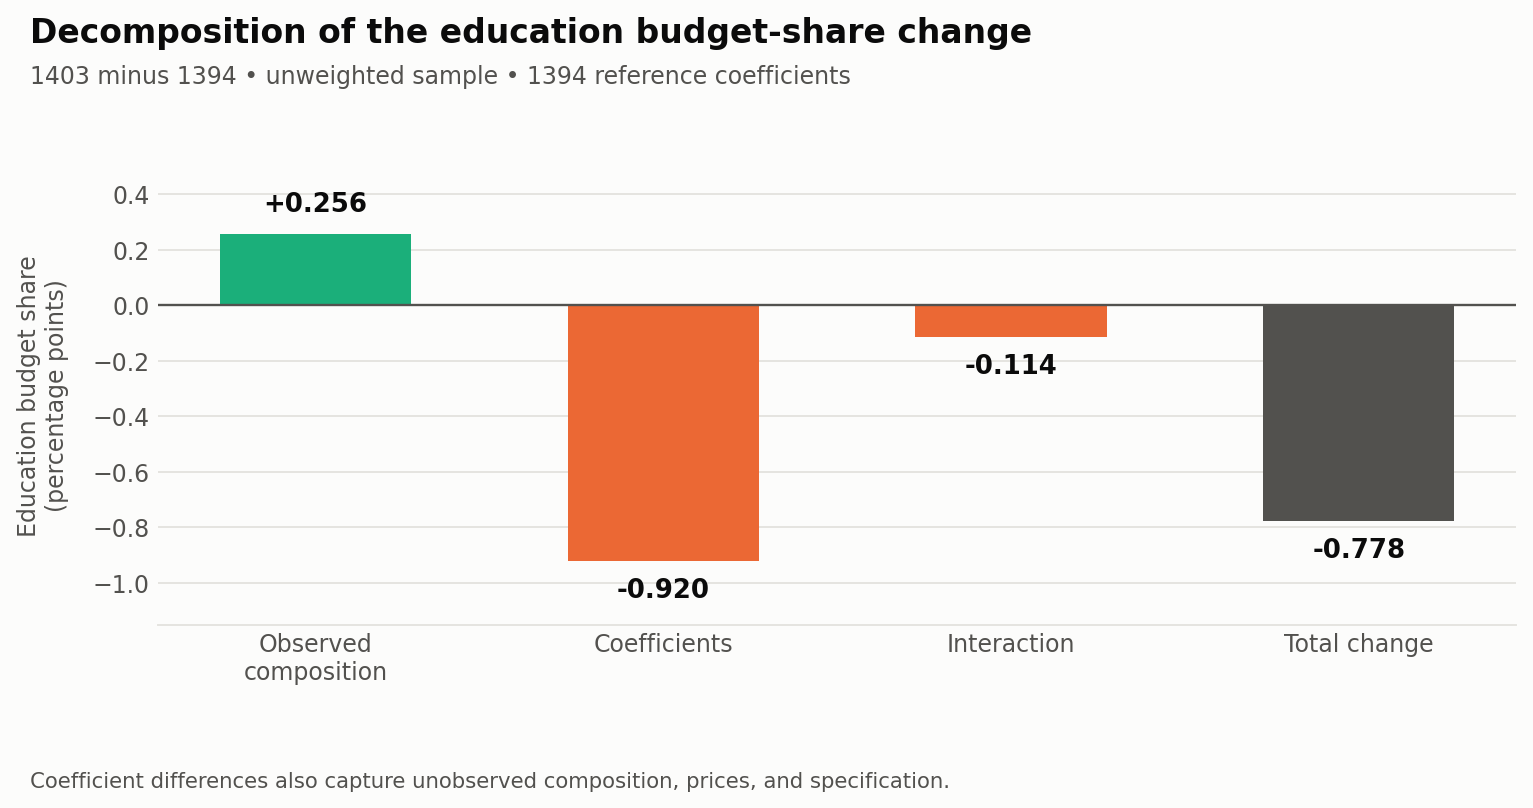

In [36]:
d_ob = d.assign(exp_rank=d.groupby("year").totexp.rank(pct=True))
OB_F = ("w_edu ~ exp_rank + ln_stu + kids + fsize + age + age2 + female_head + urban + owner + "
        "C(edulev, Treatment('Illiterate')) + C(occ, Treatment('Private employee')) + "
        "C(structure, Treatment('Nuclear (2 adults)'))")

y_all, X_all = patsy.dmatrices(OB_F, data=d_ob, return_type="dataframe")
info = X_all.design_info
parts = {}
for yy in (1394, 1403):
    sub = d_ob[d_ob.year == yy]
    Xy = patsy.build_design_matrices([info], sub, return_type="dataframe")[0]
    parts[yy] = (sub.w_edu.to_numpy(), Xy)

b, Xm = {}, {}
for yy in (1394, 1403):
    yv_, Xy = parts[yy]
    b[yy] = np.linalg.lstsq(Xy.to_numpy(), yv_, rcond=None)[0]
    Xm[yy] = Xy.to_numpy().mean(axis=0)

dx, db = Xm[1403] - Xm[1394], b[1403] - b[1394]
endow, coeff, inter = dx @ b[1394], Xm[1394] @ db, dx @ db
total = parts[1403][0].mean() - parts[1394][0].mean()
assert abs(endow + coeff + inter - total) < 1e-8, "Oaxaca–Blinder does not add up"

ob = pd.DataFrame({
    "contribution (pp of budget share)": [100 * endow, 100 * coeff, 100 * inter, 100 * total],
    "% of the total change": [100 * endow / total, 100 * coeff / total,
                              100 * inter / total, 100.0],
}, index=["endowments (composition)", "coefficients", "interaction",
          "TOTAL observed change"])
display(save_table(ob.round(3), "t16_oaxaca_blinder"))
print(f"mean education budget share  1394: {100*parts[1394][0].mean():.3f}%   "
      f"1403: {100*parts[1403][0].mean():.3f}%   change: {100*total:+.3f} pp")
print("(unweighted sample means — the descriptive table reports weighted figures, 2.27% and "
      "1.36%.\n The components here refer to the unweighted decomposition; "
      "weighting can change the decomposition.)")

fig, ax = plt.subplots(figsize=(9.4, 4.4))
labs = ["endowments\n(composition)", "coefficients", "interaction", "TOTAL\nobserved change"]
vals = [100 * endow, 100 * coeff, 100 * inter, 100 * total]
cols = [PAL["s3"] if v > 0 else PAL["s2"] for v in vals[:3]] + [PAL["ink2"]]
ax.bar(np.arange(4), vals, color=cols, width=0.58, edgecolor=PAL["surface"], linewidth=1.6)
ax.axhline(0, color=PAL["ink2"], lw=1.2)
ax.set_xticks(np.arange(4), labs)
ax.set_ylabel("percentage points of the\neducation budget share")
lo, hi = min(vals), max(vals)
ax.set_ylim(lo - 0.20, hi + 0.16)
for i, v in enumerate(vals):
    # labels sit OUTSIDE the bar end, never over the axis tick labels
    ax.annotate(f"{v:+.3f}", xy=(i, v), xytext=(0, 8 if v > 0 else -15),
                textcoords="offset points", ha="center", va="bottom" if v > 0 else "top",
                fontsize=10, fontweight="semibold", color=PAL["ink2"])
ax.grid(axis="x", visible=False)
fig.suptitle("Figure 7 · Oaxaca–Blinder: Decomposition of the change in education budget share",
             x=0.005, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "f07_oaxaca")
plt.show()

### 11.4 Results across waves

The conventional joint test rejects equal slopes. The income interaction is +0.1071 with a province-clustered SE of 0.0727 (p = 0.1405), so that specification does not detect an income-slope difference at 5%.

The unweighted budget-share change is −0.778 percentage points after rounding. Its composition contribution is +0.256, the coefficient contribution −0.920, and the interaction −0.114. This is a different weighted target from the survey-weighted decline of 0.91 points. The decomposition does not identify why spending allocation changed.

## 12. Sensitivity checks

The following cells vary weights, sample restrictions, the schooling control, functional form, and high-share observations. Their estimates are compared with the relevant model rather than assumed to share one estimand.

In [37]:
ROB = {}
def note_rob(name, value, comment):
    ROB[name] = {"elasticity": round(float(value), 4), "comment": comment}
    print(f"  {name:44s} η = {value: .4f}   {comment}")

print("baseline for comparison")
note_rob("BASELINE  two-part, income (§7.4)", eta_inc, "income two-part reference")
note_rob("BASELINE  Working–Leser 2SLS (§10.2)", eta_wl_iv, "IV specification")

baseline for comparison
  BASELINE  two-part, income (§7.4)            η =  0.9151   income two-part reference
  BASELINE  Working–Leser 2SLS (§10.2)         η =  1.3803   IV specification


### 12.1 Survey weights

Weighted and unweighted regressions can target different descriptive projections. The comparison below reweights only the positive-spending equation. Adding its coefficient to the original participation elasticity gives a partial weighting check, not a fully weighted two-part estimate.

The printed difference-of-variances statistic is an exploratory calculation. With the two estimators' covariance unaccounted for, it should not be treated as a validated test of equal slopes.

In [38]:
wls = smf.wls(f"ln_edu ~ ln_inc + {PART}", data=POS, weights=POS.weight).fit(
    cov_type="cluster", cov_kwds={"groups": POS["province"]})
uwl = smf.ols(f"ln_edu ~ ln_inc + {PART}", data=POS).fit(
    cov_type="cluster", cov_kwds={"groups": POS["province"]})
print(f"intensive-margin elasticity, unweighted : {uwl.params['ln_inc']:.4f} "
      f"({uwl.bse['ln_inc']:.4f})")
print(f"intensive-margin elasticity, weighted   : {wls.params['ln_inc']:.4f} "
      f"({wls.bse['ln_inc']:.4f})")
gap = wls.params["ln_inc"] - uwl.params["ln_inc"]

# Hausman-type test. Under correct specification the UNWEIGHTED estimator is efficient, so
# Var(β_WLS − β_OLS) = Var(β_WLS) − Var(β_OLS) and the difference has a known standard error.
se_gap = np.sqrt(max(wls.bse["ln_inc"] ** 2 - uwl.bse["ln_inc"] ** 2, 1e-12))
z_gap = gap / se_gap
print(f"\ndifference        {gap:+.4f}   SE of the difference {se_gap:.4f}   "
      f"z = {z_gap:.2f}   p = {2*st.norm.sf(abs(z_gap)):.4f}")
print(f"Exploratory difference-of-variances comparison: estimates are "
      f"{'SIGNIFICANTLY different' if abs(z_gap) > 1.96 else 'not significantly different'}: the "
      f"the calculation does not account for estimator covariance (see text).")
note_rob("weighted (WLS) instead of unweighted",
         wls.params["ln_inc"] + ext, "intensive margin re-weighted, extensive held fixed")

# can we locate the heterogeneity? two natural candidates, neither of which is decisive
POSw = POS.assign(lw=np.log(POS.weight))
for lab, f, k in [("urban vs rural", f"ln_edu ~ ln_inc*urban + {PART}", "ln_inc:urban"),
                  ("along the sampling weight", f"ln_edu ~ ln_inc*lw + {PART}", "ln_inc:lw")]:
    hm = smf.ols(f, data=POSw).fit(cov_type="cluster", cov_kwds={"groups": POSw["province"]})
    print(f"  elasticity differs {lab:26s}: {hm.params[k]:+.4f} "
          f"(cluster SE {hm.bse[k]:.4f}, p = {hm.pvalues[k]:.3f})")

intensive-margin elasticity, unweighted : 0.7532 (0.0372)
intensive-margin elasticity, weighted   : 0.9123 (0.0630)

difference        +0.1591   SE of the difference 0.0509   z = 3.13   p = 0.0018
=> the weighted and unweighted estimates are SIGNIFICANTLY different: the constant-elasticity model is an approximation.
  weighted (WLS) instead of unweighted         η =  1.0742   intensive margin re-weighted, extensive held fixed


  elasticity differs urban vs rural            : +0.0206 (cluster SE 0.0224, p = 0.357)


  elasticity differs along the sampling weight : +0.0232 (cluster SE 0.0160, p = 0.148)


### 12.2 Wild cluster bootstrap

Apply province-level Rademacher multipliers to the log-OLS residuals, with 999 draws. The resulting percentile interval is an additional approximation for the intensive-margin coefficient; it is not a studentized bootstrap hypothesis test.

In [39]:
t0 = time.time()
yb, Xb = patsy.dmatrices(f"ln_edu ~ ln_inc + {PART}", data=POS, return_type="dataframe")
Xn, yn = Xb.to_numpy(), yb.to_numpy().ravel()
piv = np.linalg.solve(Xn.T @ Xn, Xn.T)             # cached (X'X)^-1 X'
b0 = piv @ yn
u0 = yn - Xn @ b0
gidx = POS.loc[Xb.index, "province"].to_numpy()
gs = {g: np.flatnonzero(gidx == g) for g in np.unique(gidx)}
jinc = list(Xb.columns).index("ln_inc")

Bw, wb = 999, []
for _ in range(Bw):
    v = np.ones(len(yn))
    for g, ix in gs.items():
        v[ix] = rng.choice([-1.0, 1.0])
    wb.append((piv @ (Xn @ b0 + u0 * v))[jinc])
wb = np.array(wb)
print(f"wild cluster bootstrap, B = {Bw}, {len(gs)} clusters   [{time.time()-t0:.0f}s]")
print(f"  point estimate            {b0[jinc]:.4f}")
print(f"  cluster-robust SE (§6.2)  {uwl.bse['ln_inc']:.4f}")
print(f"  wild bootstrap SE         {wb.std(ddof=1):.4f}")
print(f"  wild bootstrap 95% CI     [{np.percentile(wb,2.5):.4f}, {np.percentile(wb,97.5):.4f}]")

wild cluster bootstrap, B = 999, 31 clusters   [4s]
  point estimate            0.7532
  cluster-robust SE (§6.2)  0.0372
  wild bootstrap SE         0.0372
  wild bootstrap 95% CI     [0.6779, 0.8212]


### 12.3 Including households without enrolled students

This check removes the student restriction and uses `log1p(students)`. It changes both the population and the student-count specification.

In [40]:
full = raw.assign(
    edu=raw["Education Services"], income=raw["Income"], totexp=raw["Gross_Expenditure"],
    students=raw["Number_of_Students"], kids=raw["Number_of_Childs"],
    fsize=raw["Family_Size"], age=raw["Head_Age"], year=raw["Year"],
    female_head=(raw["Head_Sex"] == "Female").astype(int),
    urban=(raw["Urban_Rural"] == "Urban").astype(int),
    owner=raw["Tenure"].isin(["Owned_Estate_Land", "Owned_Estate"]).astype(int),
    edulev=raw["Head_Education_Level"].fillna("Illiterate"),
    province=raw["Province"], season=raw["Season"],
)
full["occ"] = np.select(
    [raw["Head_Employment_Sector"].eq("Public"),
     raw["Head_Employment_Sector"].isin(["Private", "Cooperative"]),
     raw["Head_Self_Employed_Employment_Status"].notna() |
        (raw["Head_Self_Employed_Income"].fillna(0) > 0),
     raw["Head_Activity_Status"].eq("Income_without_Work"),
     raw["Head_Activity_Status"].eq("Unemployed")],
    ["Public employee", "Private employee", "Self-employed", "Income without work", "Unemployed"],
    default="Other / inactive")
full["adults"] = full.fsize - full.kids
full["structure"] = np.select(
    [full.adults <= 1, (full.adults == 2) & (raw["Number_of_Spouses"] >= 1), full.adults >= 3],
    ["Single-parent", "Nuclear (2 adults)", "Extended (3+ adults)"], default="Other")
full = full[(full.income > 0) & (full.totexp > 0) & (full.edu <= full.totexp) &
            full.age.between(15, 99)].copy()
full["pos"] = (full.edu > 0).astype(int)
full["ln_inc"] = np.log(full.income); full["ln_exp"] = np.log(full.totexp)
full["ln_stu"] = np.log1p(full.students); full["age2"] = full.age ** 2
full["ln_edu"] = np.log(full.edu.where(full.edu > 0))

print(f"unrestricted sample: {len(full):,} households "
      f"(vs {len(d):,} in the main analysis)")
print(f"  reporting positive education spending: {100*full.pos.mean():.1f}% "
      f"(vs {100*d.pos.mean():.1f}%)")
e_f, i_f, _ = two_part(full, "ln_inc", return_parts=True)
print(f"  two-part income elasticity: extensive {e_f:.4f} + intensive {i_f:.4f} = {e_f+i_f:.4f}")
note_rob("all households (no student restriction)", e_f + i_f,
         "different population; log1p(student count)")

unrestricted sample: 75,736 households (vs 36,382 in the main analysis)
  reporting positive education spending: 35.3% (vs 71.7%)


  two-part income elasticity: extensive 0.4643 + intensive 0.7438 = 1.2080
  all households (no student restriction)      η =  1.2080   different population; log1p(student count)


The unrestricted income two-part estimate is 1.2080, compared with 0.9151 in the main sample. These estimates describe different samples.

### 12.4 Schooling control

Replace education-category indicators with approximate years assigned to each category. These are constructed values rather than the inconsistent published years field.

In [41]:
YEARS = {"Illiterate": 0, "Unofficial": 2, "Primary": 5, "Lower_Secondary": 9,
         "Higher_Secondary": 11, "Pre_University": 12, "Short_Cycle_Tertiary": 14,
         "Bachelors": 16, "Masters": 18, "Doctoral": 21}
POS_y = POS.assign(hyrs=POS.edulev.map(YEARS))
d_y = d.assign(hyrs=d.edulev.map(YEARS))
PART_Y = PART.replace("C(edulev, Treatment('Illiterate'))", "hyrs")
my = smf.ols(f"ln_edu ~ ln_inc + {PART_Y}", data=POS_y).fit(
    cov_type="cluster", cov_kwds={"groups": POS_y["province"]})
print(f"years of schooling of the head: {my.params['hyrs']:+.4f} per year "
      f"(cluster SE {my.bse['hyrs']:.4f})")
print(f"  => each extra year of the head's own schooling is associated with "
      f"{100*my.params['hyrs']:.1f}% more education spending, holding income constant")
e_y, i_y, _ = two_part(d_y, "ln_inc", ctrl=PART_Y, return_parts=True)
note_rob("linear years of schooling (not dummies)", e_y + i_y, "specification of head's education")

years of schooling of the head: +0.0448 per year (cluster SE 0.0042)
  => each extra year of the head's own schooling is associated with 4.5% more education spending, holding income constant


  linear years of schooling (not dummies)      η =  0.9330   specification of head's education


### 12.5 Quadratic share equation

Allow a squared log-expenditure term and evaluate the derivative at mean log expenditure. Compare this with the linear Working–Leser OLS result.

In [42]:
mq = smf.ols(f"w_edu ~ ln_exp + I(ln_exp**2) + {PART}", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d["province"]})
mean_lx = float(d.ln_exp.mean())
beta_at_mean = mq.params["ln_exp"] + 2 * mq.params["I(ln_exp ** 2)"] * mean_lx
print(f"quadratic term: {mq.params['I(ln_exp ** 2)']:+.6f} "
      f"(cluster SE {mq.bse['I(ln_exp ** 2)']:.6f}, p = {mq.pvalues['I(ln_exp ** 2)']:.4f})")
print(f"slope evaluated at the mean of ln(total expenditure) = {beta_at_mean:+.6f}")
print(f"  => implied elasticity at the mean = {1 + beta_at_mean/wbar:.4f}   "
      f"(linear Working–Leser OLS gave {eta_wl_ols:.4f})")
note_rob("quadratic Working–Leser (OLS)", 1 + beta_at_mean / wbar, "functional form")

quadratic term: -0.000473 (cluster SE 0.000217, p = 0.0296)
slope evaluated at the mean of ln(total expenditure) = +0.002618
  => implied elasticity at the mean = 1.1850   (linear Working–Leser OLS gave 1.1771)
  quadratic Working–Leser (OLS)                η =  1.1850   functional form


### 12.6 Tehran and high budget shares

Re-estimate the income two-part model after excluding Tehran and after trimming observations above the 99th percentile of the education share. Trimming removes observations rather than replacing their values.

In [43]:
no_teh = d[d.province != "Tehran"]
print(f"dropping Tehran: {len(d)-len(no_teh):,} households removed")
e_t, i_t, _ = two_part(no_teh, "ln_inc", return_parts=True)
note_rob("excluding Tehran province", e_t + i_t, "excludes Tehran")

cap = d.w_edu.quantile(0.99)
d_w = d[d.w_edu <= cap]
print(f"\ntrimming the education budget share at the 99th percentile ({100*cap:.1f}%): "
      f"{len(d)-len(d_w):,} households removed")
e_w, i_w, _ = two_part(d_w, "ln_inc", return_parts=True)
note_rob("trimming the top 1% of budget shares", e_w + i_w, "extreme spenders")

dropping Tehran: 1,771 households removed


  excluding Tehran province                    η =  0.8978   excludes Tehran

trimming the education budget share at the 99th percentile (14.4%): 364 households removed


  trimming the top 1% of budget shares         η =  0.9302   extreme spenders


In [44]:
rob = pd.DataFrame(ROB).T
rob["deviation from baseline"] = (rob.elasticity.astype(float) - eta_inc).round(4)
rob.loc[["BASELINE  two-part, income (§7.4)", "BASELINE  Working–Leser 2SLS (§10.2)"],
        "deviation from baseline"] = np.nan
display(save_table(rob, "t17_robustness"))

,elasticity,comment,deviation from baseline
"BASELINE two-part, income (§7.4)",0.9151,income two-part reference,NaN
BASELINE Working–Leser 2SLS (§10.2),1.3803,IV specification,NaN
weighted (WLS) instead of unweighted,1.0742,"intensive margin re-weighted, extensive held f...",0.1591
all households (no student restriction),1.2080,extensive margin now dominated by 'has a child...,0.2929
linear years of schooling (not dummies),0.9330,specification of head's education,0.0179
quadratic Working–Leser (OLS),1.1850,functional form,0.2699
excluding Tehran province,0.8978,excludes Tehran,-0.0173
trimming the top 1% of budget shares,0.9302,extreme spenders,0.0151


The income two-part estimates are 0.8978 without Tehran, 0.9302 after trimming, and 0.9330 with the alternative schooling control. Larger changes occur when the population or weighting changes. The quadratic share estimate, 1.1850, is close to the linear share estimate of 1.1771.

The summary table retains deviations from the income baseline for reference, but the different resource measures and specifications need separate interpretation.

## 13. Interpretation and limitations

The main findings are the lower weighted education budget share in 1403, the contribution of participation to the income two-part estimate, and sensitivity to the resource measure and specification. The pooled per-student estimate is inconclusive at 5%; the bottom expenditure tercile has a negative estimate.

These repeated cross-sections do not identify causal effects. Unobserved preferences, reporting errors, and selection into the student sample remain concerns. Zero spending does not imply zero schooling or parental investment. Per-student averages do not reveal allocation within a household. The IV exclusion restriction, common smearing factor, Tobit distribution, and province-level inference each impose assumptions.

Intermediate waves and child-level school-type information would help investigate when and why education's budget share changed.

### References and authorship note

Key references are Becker and Lewis (1973), Duan (1983), Santos Silva and Tenreyro (2006), and Solon, Haider, and Wooldridge (2015). Bibliographic details are in `../docs/report.md`.

AI assistance was used for plotting boilerplate and suggestions for sensitivity-check structure, as disclosed in the original notebook. The analysis includes custom-estimator checks against known special cases and `statsmodels`. Saved outputs document the earlier execution; they do not replace rerunning the analysis with the original inputs.

In [45]:
# ---- final inventory -----------------------------------------------------------------------
d.to_csv(OUT / "analysis_sample.csv", index=False)
tabs = sorted(p.name for p in TAB.glob("*.csv"))
figs = sorted(p.name for p in FIG.glob("*.png"))
print(f"analysis sample written : {OUT/'analysis_sample.csv'}  ({d.shape[0]:,} x {d.shape[1]})")
print(f"\n{len(tabs)} tables -> {TAB}")
for t in tabs:
    print("   ", t)
print(f"\n{len(figs)} figures -> {FIG}")
for f in figs:
    print("   ", f)
print(f"\nseed = {SEED}   ·   notebook complete")

analysis sample written : results/analysis_sample.csv  (36,382 x 34)

19 tables -> results/tables
    t00_wave_comparability.csv
    t01_years_of_schooling_problem.csv
    t02_sample_ladder.csv
    t03_descriptives.csv
    t04_head_education_composition.csv
    t05_zero_share_by_decile.csv
    t06_engel_curve.csv
    t06b_shares_by_group.csv
    t07_baseline_ols.csv
    t08_standard_errors.csv
    t09_vif.csv
    t10_participation.csv
    t11_bootstrap_replicates.csv
    t12_quantity_quality.csv
    t13_qq_by_tercile.csv
    t14_reconciliation.csv
    t15_chow_interactions.csv
    t16_oaxaca_blinder.csv
    t17_robustness.csv

7 figures -> results/figures
    f01_zeros.png
    f02_engel.png
    f03_who_spends.png
    f04_diagnostics.png
    f05_quantity_quality.png
    f06_reconciliation.png
    f07_oaxaca.png

seed = 20250729   ·   notebook complete
